In [1]:
import sys
 
# adding Folder_2 to the system path code/python/tfcat_tools/tfcat_tools
# sys.path.insert(0, 'tfcat_tools/')
sys.path.insert(0, '/obs/kkesri/code/python/tfcat_tools/')
sys.path.insert(0, '/obs/kkesri/code/ephem/')

In [2]:
import numpy 
import numpy.polynomial.polynomial as nppol
import glob
from tqdm import tqdm
from itertools import repeat
from datetime import datetime
from h5py import File
import multiprocessing
import os 
from scipy.io import readsav
from astropy.time import Time

from spacepy import pycdf
from matplotlib import pyplot as plt
import matplotlib.colors as colors
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
from mpl_toolkits import axes_grid1
import matplotlib.gridspec as gridspec

from scipy.interpolate import interp1d
from tfcat import TFCat
from tfcat.validate import JSONSCHEMA_URI

#from tfcat_tools.tfcat_tools.edit import merge
#from tfcat_tools.tfcat_tools.mask import Mask
from tfcat_tools.edit import merge
from tfcat_tools.mask import Mask
from tfcat_tools import FeatureCollection

from read_juno_ephemeris_from_amda import *
from jupiter_ephem import *

import pandas as pd
from scipy.stats import skewnorm


In [3]:
def data_to_hdf5(file_name: str,
                time: numpy.ndarray,
                freqs: numpy.ndarray,
                data: numpy.ndarray,):
        """
        Saves the data to disk as a pre-processed HDF5 file.
        """
        output_file = File(file_name, 'w')
        output_file.attrs.create('observer', 'Juno')

        # Has to be done differently as this is an Astropy quantity
        output_file.create_dataset('Time', data=time)
        output_file['Time'].attrs.create('units', 'unix')

        output_file.create_dataset('Frequency', data=freqs)
        output_file['Frequency'].attrs.create('units',  'kHz')

        output_file.create_dataset('Data', data=data)
        output_file['Data'].attrs.create('units',  'W/m2/Hz')


        output_file.close()

def load_hdf5_data(file_name: str):
    """
    Reads a datafile in HDF5 format using the config file set earlier.
    """
    file: File = File(file_name)
    time = file['Time']
    freqs = file['Frequency']
    flux = file['Flux']
    return time, freqs, flux



def nozeros(x):
    return numpy.where(x != 0, x, 1)

def xyz_to_rtp(xyz):
    rtp = numpy.zeros(shape=xyz.shape)
    rtp[..., 0] = numpy.sqrt(xyz[..., 0]**2+xyz[..., 1]**2+xyz[..., 2]**2)
    rtp[..., 1] = numpy.arcsin(xyz[..., 2]/nozeros(rtp[..., 0]))*180/numpy.pi
    rtp[..., 2] = numpy.arctan2(xyz[..., 1], xyz[..., 0])*180/numpy.pi
    return rtp

def set_ephemeris(time, ephemeris, local_time_ephemeris):
    tmin, tmax = time.min(), time.max()
    new_ephemeris_time = ephemeris[0][(ephemeris[0] >= tmin) & (ephemeris[0] <= tmax)]
    new_local_time_ephemeris_time = local_time_ephemeris[0][(local_time_ephemeris[0] >= tmin) & (local_time_ephemeris[0] <= tmax)]
    _ephemeris_xyz = numpy.zeros(shape=(time.shape[0],3))
    _local_time_ephemeris_xyz = numpy.zeros(shape=(time.shape[0],3))
    for i in range(3) :
        _ephemeris = ephemeris[i+1][(ephemeris[0] >= tmin) & (ephemeris[0] <= tmax)]
        _ephemeris_xyz[:, i] = numpy.interp(time, new_ephemeris_time, _ephemeris)
        
        _ephemeris = local_time_ephemeris[i+1][(local_time_ephemeris[0] >= tmin) & (local_time_ephemeris[0] <= tmax)]
        _local_time_ephemeris_xyz[:, i]  = numpy.interp(time, new_local_time_ephemeris_time, _ephemeris)
        
    _ephemeris = numpy.zeros(shape=(time.shape[0],4))
    _ephemeris[:, 0:3] = xyz_to_rtp(_ephemeris_xyz)
    del _ephemeris_xyz
    _local_time_ephemeris = xyz_to_rtp(_local_time_ephemeris_xyz)
    _ephemeris[:, 3] = _local_time_ephemeris[:, 2]
    return _ephemeris

In [4]:

@numpy.vectorize
def webgeocalc_date_to_datetime(date_YMD,date_hours):
    return datetime.datetime.strptime(date_YMD+"T"+date_hours,"%Y-%m-%dT%H:%M:%S.%f")

@numpy.vectorize
def unix_date_to_datetime(date_unix):
    return datetime.datetime.fromtimestamp(date_unix)


def juno_ephemeris_from_webgeocalc(file, planetary_radius=False):
    if planetary_radius == False:
        print("### User needs to give a planetary radius to have ephemeris in planetary units ###")
    data_file = numpy.loadtxt(file,dtype="str")
    date = webgeocalc_date_to_datetime(data_file[:,0],data_file[:,1])
    x_coord = data_file[:,5].astype(float)
    y_coord = data_file[:,6].astype(float)
    z_coord = data_file[:,7].astype(float)

    return (date,x_coord[:]/planetary_radius,y_coord[:]/planetary_radius,z_coord[:]/planetary_radius)


In [5]:
# Function to read and concatenate variables from HDF5 files
def concatenate_hdf5_files(file_list, variable_names, path_files = './'):
    concatenated_data = {var: [] for var in variable_names}

    for file in file_list:
        with File(path_files+file, 'r') as f:
            for var in variable_names:
                concatenated_data[var].append(f[var][:])

    # Concatenate lists into numpy arrays
    concatenated_data = {var:numpy.concatenate(concatenated_data[var], axis=0) for var in variable_names}

    return concatenated_data


In [6]:
# Function to recursively flatten the nested structure
def flatten(nested_list):
    flat_list = []
    for item in nested_list:
        if isinstance(item, list):
            flat_list.extend(flatten(item))
        else:
            flat_list.append(item)
    return flat_list

In [7]:
def sort_cat(cat: TFCat):
    crs = cat.crs
    properties = cat.properties
    fields= cat.data.fields
    schema = cat.data["$schema"]
    event = FeatureCollection(cat.data, properties=properties, fields=fields, crs=crs, schema=schema).as_table()
    event.sort(['tmin'])
    return TFCat(FeatureCollection().from_table(table=event, properties=properties, fields=fields, crs=crs, schema=schema))



In [8]:
def load_intensity_from_hdf5_file(file_name: str):
    """
    Reads a datafile in HDF5 format using the config file set earlier.
    """
    file: File = File(file_name)
    normalized_intensity_bKOM = numpy.array(file['normalized_intensity_bKOM'])

    return normalized_intensity_bKOM       

In [9]:
from spacepy import pycdf
def load_background_data(cdf_file_path):
    with pycdf.CDF(cdf_file_path) as cdf_file:
        background = numpy.array(cdf_file["Background"])
        sigma = numpy.array(cdf_file["Sigma"])
        frequency = numpy.array(cdf_file["Frequency"])
        
        #for attr in cdf_file["Background"].attrs:        
        #    print(f"{attr}: {cdf_file['Background'].attrs[attr]}")
    
    return background, sigma, frequency


In [10]:
#thresholding data
def thresholding_data(data,background):

    occurrence = numpy.zeros(data.shape)
    for ifreq in range(len(background)):
        mask = data[:, ifreq] > background[ifreq]
        occurrence[mask, ifreq] = 1
    return occurrence

In [11]:
@numpy.vectorize
def from_UTC_to_astropy_Time(time_UTC):
    return Time(time_UTC[:-4]).unix

In [12]:
from webgeocalc import Calculation

def get_ephem_from_wgc(observer, time, api = None):
    """
    Get ephemeris data from WGC servers through API
    :param observer:
    :type observer: dict
    :param time:
    :type time: dict
    :return:
    :rtype: dict
    """

    wgc_kernels = [
                    "pds/wgc/mk/ground_stations_v0018.tm",
                    "pds/wgc/mk/solar_system_v0056.tm",
                    "pds/wgc/mk/latest_lsk_v0004.tm",
                    ]

    time_interval = [time['time_start'].strftime("%Y-%m-%d %H:%M:%S"), time['time_end'].strftime("%Y-%m-%d %H:%M:%S")]                    

    if api == None:
        api = ''
    elif api.lower() == 'obspm':
        api = 'https://voparis-webgeocalc2.obspm.fr/geocalc/api'
        #api = "https://wgc.jpl.nasa.gov:8443/webgeocalc/api"
        #api = 'https://wgc.obspm.fr/webgeocalc/api'
    calc = Calculation(
        api = api,
        kernel_paths =  wgc_kernels,
        intervals = time_interval,
        time_step = time['time_step'],
        time_step_units = time['time_units'],
        calculation_type = 'STATE_VECTOR',
        target = observer['NAME'],
        observer = observer['PARENT'],
        reference_frame = observer['referenceFrame'],
        aberration_correction = 'NONE',
        state_representation = 'PLANETOGRAPHIC',
    )

    calc.payload
    calc.run()

    longitude = numpy.array(calc.results['LONGITUDE'])  # must be in LongW for ExPRES
    latitude = numpy.array(calc.results['LATITUDE'])
    distance = numpy.array(calc.results['ALTITUDE'])
    time_ephem = numpy.array(calc.results['DATE'])

    result_data = {
                    'time': time_ephem,
                    'longitude': -longitude, # So that the longitude is counting West (SIII for Jupiter)
                    'latitude': latitude,
                    'distance': distance,

                }
    return result_data
    

Path to data, catalogue and ephemeris files

In [13]:
#PATHS
year = [2016,2017,2018,2019,2020,2021]
#year = [2020,2021]
path_cat = {f'{iyear}': f'/obs/kkesri/code/data/TFCat_catalog_2.1/juno_waves_lira_tfcat_{iyear}.json' for iyear in year}
path_dir_data  = '/obs/juno_data_preprocessed/'
path_dir_ephem = '/obs/kkesri/code/ephem/'
data_path_IAU_ephemeris = f"{path_dir_ephem}juno_jup_xyz_iau_2016_2025.txt"
data_path_JSO_ephemeris = f"{path_dir_ephem}juno_jup_xyz_jso_2016_2025.txt"

Definition of output path and keywords

In [14]:
directory_path_out = 'outputs/'
savefig = True

Constants Definition

In [15]:
AU = 149597870.700 # 1 astronomical unit in km
RJ = 71492. # Jovian radius in km

Loading Ephemeris

In [16]:
all_ephemeris = juno_ephemeris_from_amda(data_path_IAU_ephemeris)
local_time_ephemeris = juno_ephemeris_from_amda(data_path_JSO_ephemeris)

#print(threshold)

Time range definition

In [17]:
time_start = datetime.datetime(2016,6,1)
time_end = datetime.datetime(2021, 3, 1, 0, 0, 0) # or After datetime.datetime(2021, 9, 1, 0, 0, 0). Gap inbetween

Dates for Louis et al. 2021

In [ ]:
time_start = datetime.datetime.strptime("2016100","%Y%j")
time_end = datetime.datetime.strptime("2019172", "%Y%j")

HDF5 data files reading

In [18]:
hdf5_files_2016 = ["jno_wav_cdr_lesia_2016_apr_aug.preprocessed.hdf5",
"jno_wav_cdr_lesia_2016_sep_dec.preprocessed.hdf5"]
hdf5_files_2017 = ["jno_wav_cdr_lesia_2017_jan_apr.preprocessed.hdf5",
"jno_wav_cdr_lesia_2017_may_aug.preprocessed.hdf5",
"jno_wav_cdr_lesia_2017_sep_dec.preprocessed.hdf5"]
hdf5_files_2018 = ["jno_wav_cdr_lesia_2018_jan_apr.preprocessed.hdf5",
"jno_wav_cdr_lesia_2018_may_aug.preprocessed.hdf5",
"jno_wav_cdr_lesia_2018_sep_dec.preprocessed.hdf5"]
hdf5_files_2019 = ["jno_wav_cdr_lesia_2019_jan_apr.preprocessed.hdf5",
"jno_wav_cdr_lesia_2019_may_aug.preprocessed.hdf5",
"jno_wav_cdr_lesia_2019_sep_dec.preprocessed.hdf5"]
hdf5_files_2020 = ["jno_wav_cdr_lesia_2020_jan_apr.preprocessed.hdf5",
"jno_wav_cdr_lesia_2020_may_aug.preprocessed.hdf5",
"jno_wav_cdr_lesia_2020_sep_dec.preprocessed.hdf5"]
hdf5_files_2021 = ["jno_wav_cdr_lesia_2021_jan_apr.preprocessed.hdf5",
"jno_wav_cdr_lesia_2021_may_aug.preprocessed.hdf5",
"jno_wav_cdr_lesia_2021_sep_dec.preprocessed.hdf5"]

# /!\ be careful, do not take into account beg. of 2021. bKOM is inverse mask, so if catalogue not done, mask takes everything
# /!\ do not take data at PJ, so wh en d < 2 R_Jupiter

# Dictionary to hold file lists for each year
files_dict = {
    2016: hdf5_files_2016,
    2017: hdf5_files_2017,
    2018: hdf5_files_2018,
    2019: hdf5_files_2019,
    2020: hdf5_files_2020,
    2021: hdf5_files_2021,
}


# Variables to concatenate
variables = ['Flux', 'Time']

# Dictionary to store concatenated data for each year
yearly_data = {}

# Process each year
for iyear, files in files_dict.items():
    yearly_data[iyear] = concatenate_hdf5_files(files, variables, path_files = path_dir_data)


Frequency reading

In [19]:
with File(path_dir_data+hdf5_files_2016[0]) as hdf_file:
    Frequency = numpy.array(hdf_file['Frequency'])

Data variables and TFCat catalogues sorting and creation of dictionnaries

In [20]:
file_name_hdf5 = {f'{iyear}': f'mask_{iyear}.hdf5' for iyear in year}
cat = {f'{iyear}': sort_cat(TFCat.from_file(path_cat[f'{iyear}'])) for iyear in year}
for iyear in year:
    cat[f'{iyear}'].properties['instrument_name'] = "Waves_" 

time = {f'{iyear}': numpy.array(Time(yearly_data[iyear]['Time'], format="jd").unix) for iyear in year}
data = {f'{iyear}': numpy.array(yearly_data[iyear]['Flux']) for iyear in year}

Selection in time

In [21]:
mask_time_start = time[time_start.strftime("%Y")] >= Time(time_start,format="datetime").unix
time[time_start.strftime("%Y")] = time[time_start.strftime("%Y")][mask_time_start]
data[time_start.strftime("%Y")] = data[time_start.strftime("%Y")][mask_time_start,:]

In [22]:
mask_time_end = time[time_end.strftime("%Y")] <= Time(time_end,format="datetime").unix
time[time_end.strftime("%Y")] = time[time_end.strftime("%Y")][mask_time_end]
data[time_end.strftime("%Y")] = data[time_end.strftime("%Y")][mask_time_end,:]

Ephemerides calculation only on the wanted time range

In [23]:
time_arrays = list(time.values())
time_over_year_sec = numpy.concatenate(time_arrays)
# Normalization at 1 AU
mask_time = (all_ephemeris[0]>= time_start) & (all_ephemeris[0]< time_end)
ephem_x = all_ephemeris[1][mask_time]
ephem_y = all_ephemeris[2][mask_time]
ephem_z = all_ephemeris[3][mask_time]
ephem_date = all_ephemeris[0][mask_time]

distance = numpy.sqrt(ephem_x**2 + ephem_y**2 + ephem_z**2)
lat = (numpy.pi-numpy.arccos(ephem_z / distance)) * 180/numpy.pi
lon = numpy.pi-numpy.arctan2(ephem_y,ephem_x) * 180/numpy.pi

distance = numpy.sqrt(ephem_x**2 + ephem_y**2 + ephem_z**2)
lat = 90 - (numpy.arccos(ephem_z / distance))*180/numpy.pi 
lon = (360 - ((numpy.arctan2(ephem_y,ephem_x))*180/numpy.pi)) % 360



time_ephem_sec = Time(ephem_date, format='datetime').unix
oblon=numpy.interp(time_over_year_sec,time_ephem_sec,lon)
oblat=numpy.interp(time_over_year_sec,time_ephem_sec,lat) 
obdist=numpy.interp(time_over_year_sec,time_ephem_sec,distance)
obmlat=10.31*numpy.cos((196.61-oblon)*numpy.pi/180.)+oblat

In [24]:
print(Time(time_over_year_sec[0], format = "unix").isot, Time(time_over_year_sec[-1], format = "unix").isot,
        Time(time_ephem_sec[0], format = "unix").isot, Time(time_ephem_sec[-1], format = "unix").isot)

2016-06-01T00:00:08.184 2021-02-28T23:59:09.184 2016-06-01T00:05:00.000 2021-02-28T23:55:00.000


Frequency range selection

In [25]:
#time_index = numpy.where((time.datetime >= time_start) & (time.datetime < time_end))[0]

index_freq_LFR = numpy.where((Frequency > 1) & (Frequency < 142))[0][0:-1]
index_freq_bKOM = numpy.where((Frequency > 10) & (Frequency < 142))[0][0:-1]
index_freq_DAM = numpy.where(Frequency >3000)[0]

Calculating or loading normalized_intensity_bKOM

In [26]:
calculate_intensity = False
if calculate_intensity:
    intensity_bKOM_list = []

    for index, iyear in enumerate(year):
        print(f"{iyear}")
        mask_juno_bKOM = Mask(
                            cat[f'{iyear}'],
                            time[f'{iyear}'],
                            Frequency[index_freq_bKOM],
                            data[f'{iyear}'][:,index_freq_bKOM]
                            )

        mask_juno_bKOM_data =  mask_juno_bKOM.apply('QP','nLF','nKOM','QP?','nLF?','nKOM?','anom',invert=True)
        mask_juno_bKOM_data = mask_juno_bKOM_data * 377
        #integrated_intensity_bKOM = numpy.sum(mask_juno_bKOM_data, axis=1)

        intensity_bKOM_list.append(mask_juno_bKOM_data)

        #if index == 0:
        #    integrated_intensity_bKOM_over_year = integrated_intensity_bKOM
        #else:
        #    integrated_intensity_bKOM_over_year = [integrated_intensity_bKOM_over_year, integrated_intensity_bKOM]
    intensity_bKOM_over_year = numpy.concatenate(intensity_bKOM_list)

    #integrated_intensity_bKOM_over_year_flattened_arrays = flatten(integrated_intensity_bKOM_over_year)
    #normalized_integrated_intensity_bKOM = numpy.concatenate(integrated_intensity_bKOM_over_year_flattened_arrays)*(obdist/AU)**2
    normalized_intensity_bKOM = intensity_bKOM_over_year * (obdist[:, numpy.newaxis]*RJ / AU)**2    

    output_file = File('normalized_intensity_bKOM.hdf5', 'w')
    output_file.attrs.create('observer', 'Juno')
    output_file.create_dataset('normalized_intensity_bKOM', data=normalized_intensity_bKOM)
    output_file['normalized_intensity_bKOM'].attrs.create('units', 'W/m2/Hz@1AU')
    output_file.close()
else:
    normalized_intensity_bKOM = load_intensity_from_hdf5_file("/obs/kkesri/code/data/normalized_intensity_bKOM_catalog_v20.hdf5")


Filtering with distance

In [27]:
mask_distance = obdist < 10
normalized_intensity_bKOM[mask_distance,:] = numpy.nan

Loading background data

In [28]:
cdf_file_path = "/Users/clouis/Documents/Data/Juno/Waves/2021/12/jno_wav_cdr_lesia_20211201_v02.cdf"
background, sigma_background, frequency_background = load_background_data(cdf_file_path)
# selection in frequency and /377 for V^2/m^2/Hz --> W/m^2/Hz
background = background[index_freq_bKOM]/377
sigma_background = sigma_background[index_freq_bKOM]

CDFError: NO_SUCH_CDF: The specified CDF does not exist.

Calculating background from normalized_intensity_bKOM data

In [28]:
background_from_data = numpy.zeros(normalized_intensity_bKOM.shape[1])
for ifreq in range(normalized_intensity_bKOM.shape[1]):
    mask = normalized_intensity_bKOM[:,ifreq] > 0
    background_from_data[ifreq] =  numpy.nanmean(normalized_intensity_bKOM[mask, ifreq])
    

Calculating integrated intensity over frequency

In [29]:
normalized_integrated_intensity_bKOM = numpy.sum(normalized_intensity_bKOM, axis=1)
    

Calculating integrated occurrence over frequency using background data

In [30]:
occurrence = thresholding_data(normalized_intensity_bKOM, background_from_data)
integrated_occurrence = numpy.sum(occurrence, axis = 1)
mask = integrated_occurrence > 0
integrated_occurrence[mask] = 1

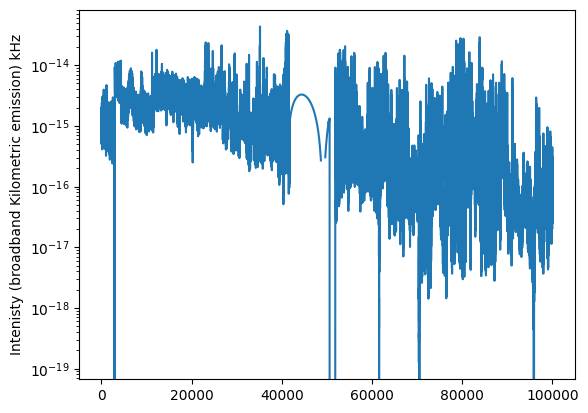

In [31]:
plt.plot(normalized_integrated_intensity_bKOM[0:100000])
plt.ylabel('Intenisty (broadband Kilometric emission) kHz')
plt.yscale('log')
plt.show()

## Incorporating Matt's data and Juno's Data together

In [32]:
time_datetime = pd.to_datetime(time_over_year_sec, unit='s')

Resampling the Juno data to change the resolution from 1 min to 1 hour (roughly)

case = 0: When you want all the arrays sliced according to the timestamps of your choosing

case = 1: When you just the entire resampled/original data


In [33]:
def resample_hourly(start, end, case): 
    df_juno = pd.DataFrame({ 
        "time": pd.to_datetime(time_over_year_sec, unit='s'), 
        "intensity": normalized_integrated_intensity_bKOM 
        }) 
    
    df_juno.set_index("time", inplace=True) 
    df_hourly = df_juno.resample("1H").mean() 
    
    df_dist = pd.DataFrame({ 
        "time": pd.to_datetime(time_over_year_sec, unit='s'), 
        "dist": obdist 
        }) 
    
    df_dist.set_index("time", inplace=True) 
    df_dist_hourly = df_dist.resample("1H").mean() 
    df_combined = df_hourly.join(df_dist_hourly) 
    df_subset = df_combined.loc[start:end] 
    
    time_subset = df_subset.index 
    intensity_subset = df_subset["intensity"] 
    dist_subset = df_subset["dist"] 
    
    if case == 0:  # Gives back only the sliced data
        return time_subset, intensity_subset, dist_subset
    
    if case == 1:  # Gives back the entire dataset
        return df_hourly
    

def sample_minute(start, end, case):
    if case == 0:  # Gives back the sliced data
        mask = (time_datetime >= start) & (time_datetime <= end)

        time_subset = time_datetime[mask]
        intensity_subset = normalized_integrated_intensity_bKOM[mask]
        dist_subset = numpy.array(obdist)[mask]
        
        return time_subset, intensity_subset, dist_subset
    
    if case == 1:  # Gives back the entire dataset
        time = time_datetime
        intensity = normalized_integrated_intensity_bKOM
        dist = numpy.array(obdist)

        return time, intensity, dist

Choosing to mark only a few equally spaced date, time and position coordinates in the entire interval 

In [34]:
def ticks(time_subset, dist_subset):
    n_ticks = 8
    indices = numpy.linspace(0, len(time_subset)-1, n_ticks, dtype=int)

    tick_times = time_subset[indices]
    tick_labels = [
        f"{t.strftime('%Y-%m-%d')}\n{d:.2f} Rj"
        for t, d in zip(tick_times, dist_subset[indices])
    ]
    return tick_times, tick_labels

Reading Matt's File

In [35]:
def readMMESH_fromFile(fullfilename):
    """
    Parameters
    ----------
    fullfilename : string
        The fully qualified (i.e., absolute) filename pointing to the MMESH 
        output .csv file

    Returns
    -------
    mmesh_results : pandas DataFrame
        The results of the MMESH run
    """
    
    #   Read the csv, parsing MultiIndex columns correctly
    mmesh_results = pd.read_csv(fullfilename, 
                                comment='#', header=[0,1], index_col=[0])
    
    #   Reset the index to be datetimes, rather than integers
    mmesh_results.index = pd.to_datetime(mmesh_results.index)
    
    return mmesh_results

output = readMMESH_fromFile("/obs/kkesri/code/data/MMESH_data/MMESH_JupiterMME.csv")
df=pd.DataFrame(output)

Slicing the data columns according to our interval of interest, for Matt's data

In [36]:
def MMESH_slicing(start, end, diag: str):
    diag_available = ['B_mag','B_mag_a', 'B_mag_loc', 'B_mag_scale', 
                      'n_tot','n_tot_a', 'n_tot_loc', 'n_tot_scale',
                      'P_dyn','P_dyn_a', 'P_dyn_loc', 'P_dyn_scale',
                      'u_mag','u_mag_a', 'u_mag_loc', 'u_mag_scale']
    
    if diag not in diag_available:
        return df.loc[start:end]
        #raise ValueError(f"{diag} not found")
    
    i = diag_available.index(diag)
    return df.loc[start:end, df.columns[i]]

Function defined to higlight a certain stripped area in the timeseries which has to be either excluded or included. 

If you want to show excluded or deleted data: choose case = 0

If you want to show special or inclusive data: choose case = 1

In [37]:
def highlighted_regions(parameter, quantity, case, time):
    if case == 0:
        mask_excluded = quantity < parameter
    if case == 1:
        mask_excluded = quantity > parameter
    
    excluded_regions = []
    in_region = False
    region_start = None  

    for i in range(len(mask_excluded)):
        if mask_excluded[i] and not in_region:
            region_start = time[i]  
            in_region = True
        elif not mask_excluded[i] and in_region:
            region_end = time[i]    
            excluded_regions.append((region_start, region_end))
            in_region = False

    if in_region:
        excluded_regions.append((region_start, time[-1]))

    return excluded_regions

# Interatcions of Solar wind and Jovian Magnetosphere

(A) Choosing the specific timeframe where we want to work

In [38]:
start = pd.Timestamp("2016-12-01 00:00:00")
end   = pd.Timestamp("2017-01-31 22:00:00")

df_hourly = resample_hourly(start, end, 1)
df_hourly1 = df_hourly[start:end]

In [39]:
# ---------------------------
# Juno data
# ---------------------------

juno_data = resample_hourly(start, end, 0)  # for hourly resolution of Juno
#juno_data = sample_minute(start, end, 0)  # for the original resolution of Juno, i.e., ~60 seconds
time_subset = juno_data[0]
intensity_subset = juno_data[1]
dist_subset = juno_data[2]

# ---------------------------
# Matt's data
# ---------------------------

P_dyn = MMESH_slicing(start, end, 'P_dyn')  # Solar wind Dynamic Pressure Dataset
B_mag = MMESH_slicing(start, end, 'B_mag')  # Magnetic Field Dataset
u_mag = MMESH_slicing(start, end, 'u_mag')  # Solar Wind Velocity Dataset
n_tot = MMESH_slicing(start, end, 'n_tot')  # Number Density Dataset
timestamps = MMESH_slicing(start, end, '1').index  # Time Series Index 

/tmp/ipykernel_121936/153161509.py:17: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[0].set_xticklabels(x_marker[0],fontsize=7)


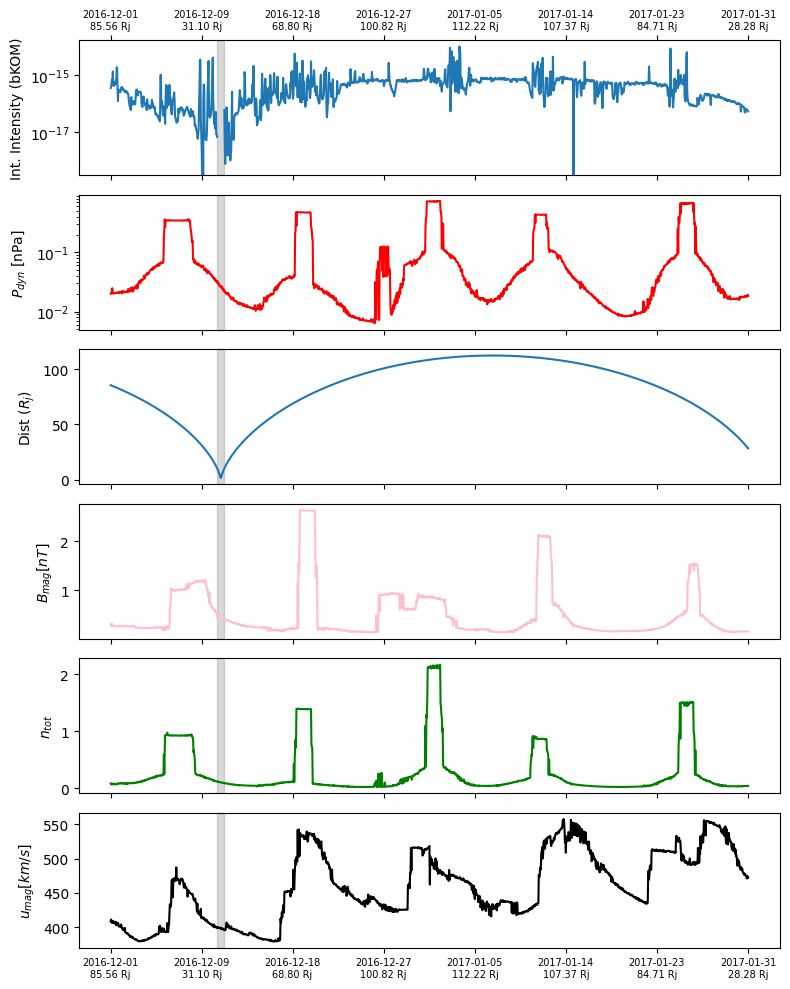

In [40]:
# -----------------
# Plotting the entire raw ensemble of datasets we have 
# -----------------

x_marker = ticks(time_subset, dist_subset)

# Create vertically stacked subplots with shared x-axis
fig, axs = plt.subplots(6, 1, sharex=True, figsize=(8, 10))

# Juno's Data
axs[0].plot(time_subset,intensity_subset)
axs[0].set_yscale('log')
axs[0].set_ylabel("Int. Intensity (bKOM)")
axs[0].grid(False)
axs[0].xaxis.set_ticks_position('both')
axs[0].tick_params(labeltop=True)
axs[0].set_xticklabels(x_marker[0],fontsize=7)

# Matt's Data

# Solar Wind Dynamic Pressureint(obdist.shape)
axs[1].plot(timestamps, P_dyn, color='red', label='$P_{dyn}$')
axs[1].set_ylabel("$P_{dyn}$ [nPa]")
axs[1].set_yscale('log')

# Juno's Distance to Jupiter
axs[2].plot(time_subset, dist_subset)
axs[2].set_ylabel('Dist ($R_j$)')

# Magnetic field
axs[3].plot(timestamps, B_mag, color='pink', label='$B_{mag}$')
axs[3].set_ylabel("$B_{mag} [nT]$")

# Particle Density
axs[4].plot(timestamps, n_tot, color='green', label='$n_{tot}$')
axs[4].set_ylabel("$n_{tot}$")

# Solar Wind Velocity
axs[5].plot(timestamps, u_mag, color='black', label='$u$')
axs[5].set_ylabel("$u_{mag} [km/s]$")

# Higlighting the unused data when JUNO was very close to the Jupiter, in our case = 10 Rj
excluded_regions = highlighted_regions(10, dist_subset, 0, time_subset)
for ax in axs:
    for (region_start, region_end) in excluded_regions:
        ax.axvspan(region_start, region_end, color='grey', alpha=0.3)

'''_____________________________________________________________________
ax_corr = axs[0].twinx()

ax_corr.plot(time_subset, rolling_corr, color='black', alpha=0.4)
ax_corr.set_ylabel("Corr", color='black')
ax_corr.set_ylim(-1, 1)
#______________________________________________________________________'''

# Tight layout for spacing
plt.xticks(x_marker[0], x_marker[1], size=7)
plt.tight_layout()
plt.show()

Initiating the statistical comparision between the two datasets

(B) Intialising relevant parameters

In [41]:
import numpy as np

# -----------------------------------------------------------------------------
# PARAMETERS (keep these explicit so you can tune easily)
# -----------------------------------------------------------------------------

# -- Parameters for part A --
SMOOTH_P = 3                  # smoothing for P_dyn
DERIV_THRESHOLD = 0.02        # threshold for sharp rise dP/dt (tuneable!)
PLATEAU_FRACTION = 0.8        # for P_dyn plateau hunt
MIN_EVENT_DURATION = 3        # minimum duration (hours)

# -- Parameters for part B -- 
# Layer 1: response-search window
BKOM_SEARCH_WINDOW = 24       # ±24 h around event midpoint

# Layer 2: active-duration search
ACTIVE_SEARCH_AFTER = 70      # hard Jovian-week cutoff
ACTIVE_FRACTION = 0.5         # threshold relative to response jump
COMPARABLE_FRACTION = 0.7     # future peaks must be at least 70% of main jump
QUIET_HOURS = 6               # must stay quiet this long before ending
LOOKAHEAD_HOURS = 12          # search for future comparable peaks    

# -- Parameters for part D -- 
MIN_RESPONSE_RATIO = 3        # minimum jump ratio
MIN_CORR = 0.3                # minimum acceptable correlation
ROLLING_WINDOW = 5           # hours for correlation window
RJ_LIMIT = 10                 # reject events below this distance.

In [42]:
# Juno distance series
r_series = pd.Series(obdist, index=pd.to_datetime(time_over_year_sec, unit='s')).sort_index()

(C) Including the actual Jupiter-Sun-Earth Angles 

In [43]:
path = '/obs/kkesri/code/data/output-jup_sw_da_2016.txt'

def JSE():
    data_file = numpy.loadtxt(path, dtype="str")
    dates = amdadate_to_datetime(data_file[:, 0][:])
    angles = data_file[:, 1].astype(float)
    return (dates, angles)

JSE_data = JSE()
jse_dates, jse_angles = JSE_data

df_jse = pd.DataFrame({
    "time": pd.to_datetime(jse_dates),
    "angle": jse_angles
})
df_jse.set_index("time", inplace=True)

# Option A: Replace outliers with NaN (keeps index intact, good for plotting) 
# df_jse["angle"] = df_jse["angle"].where(df_jse["angle"].between(-180, 180), other=numpy.nan)

# Option B: Replace with NaN then interpolate (smoothly fills gaps) 
df_jse["angle"] = df_jse["angle"].where(df_jse["angle"].between(-180, 180), other=numpy.nan)
df_jse["angle"] = df_jse["angle"].interpolate(method="time")

jse_angles = df_jse['angle']; jse_dates = df_jse.index

df_jse.index= pd.to_datetime(df_jse.index)
df_jse_subset= df_jse[start:end]
#print(df_jse_subset)

(D) Event detection in Solar wind (MMESH), events in P_dyn (using derivatives)

In [44]:
# -----------------------------------------------------------------------------
# A. DETECT EVENTS IN P_dyn
# -----------------------------------------------------------------------------

P_smooth = P_dyn.rolling(SMOOTH_P, center=True, min_periods=1).mean()

#First order derivative
dP = P_smooth.diff()

# Identify where derivative is strongly positive
rising = dP > DERIV_THRESHOLD

events = []

in_event = False
start_time = None

for t in rising.index:

    # EVENT START
    if rising.loc[t] and not in_event:

        in_event = True
        start_time = t

    # EVENT END OF RISE
    elif not rising.loc[t] and in_event:

        rise_end = t
        rise_duration = (rise_end - start_time).total_seconds()/3600

        if rise_duration >= MIN_EVENT_DURATION:

            # Find peak within rise interval
            rise_window = P_smooth.loc[start_time:rise_end]

            event_peak_time = rise_end
            event_peak_value = rise_window.max()

            # Plateau detection
            threshold = (PLATEAU_FRACTION * event_peak_value)
            after_peak = P_smooth.loc[event_peak_time:]
            plateau_end = after_peak.index[-1]

            for tt, val in after_peak.items():

                if val < threshold:
                    plateau_end = tt
                    break

            plateau_duration = (plateau_end - event_peak_time).total_seconds()/3600

            forcing_duration = (plateau_end - start_time).total_seconds()/3600

            midpoint = (start_time + (rise_end - start_time)/2)

            events.append({
                # rise interval
                "event_start": start_time,
                "event_end": rise_end,
                "event_midpoint": midpoint,
                "event_duration_hr": rise_duration,

                # plateau
                "plateau_end": plateau_end,
                "plateau_duration_hr": plateau_duration,

                # total forcing
                "forcing_duration_hr": forcing_duration

            })

        in_event = False

df_events = pd.DataFrame(events)

if not df_events.empty:
    df_events = df_events.set_index("event_midpoint")

print(df_events.shape)

(7, 6)


(E) Response detection in JUNO/bKOM 

In [45]:
# -----------------------------------------------------------------------------
# B. FIND RESPONSE IN bKOM + ACTIVE PERIOD
# -----------------------------------------------------------------------------

bkom_results = []
used_response_times = []

for t_event in df_events.index:

    # =========================================================================
    # LAYER 1: FIND RESPONSE WITHIN ±24 h
    # =========================================================================

    response_window = df_hourly.loc[
        t_event - pd.Timedelta(hours=BKOM_SEARCH_WINDOW):
        t_event + pd.Timedelta(hours=BKOM_SEARCH_WINDOW),
        "intensity"
    ].dropna()

    if len(response_window) < 5:
        continue

    logI_response = np.log10(response_window[response_window > 0]).dropna()

    if len(logI_response) < 5:
        continue

    dlogI = logI_response.diff()
    rising = dlogI > 0

    segments = []
    current_segment = []

    for t in rising.index:
        if rising.loc[t]:
            current_segment.append(t)
        else:
            if len(current_segment) > 1:
                segments.append(current_segment)
            current_segment = []

    if len(current_segment) > 1:
        segments.append(current_segment)

    if len(segments) == 0:
        continue

    best_jump = -np.inf
    best_segment = None

    for seg in segments:
        t_start = seg[0]
        t_end = seg[-1]

        jump = logI_response.loc[t_end] - logI_response.loc[t_start]

        if jump > best_jump:
            best_jump = jump
            best_segment = (t_start, t_end)

    response_base, response_peak = best_segment

    baseline = logI_response.loc[response_base]
    peak_log = logI_response.loc[response_peak]

    jump_log = peak_log - baseline
    response_ratio = 10**jump_log

    response_midpoint = response_base + (response_peak - response_base) / 2
    response_duration_hr = (
        response_peak - response_base
    ).total_seconds() / 3600

    # Avoid duplicate response assignment
    if any(
        abs((response_midpoint - used).total_seconds() / 3600) < 6
        for used in used_response_times
    ):
        continue

    used_response_times.append(response_midpoint)

    # =========================================================================
    # LAYER 2: ACTIVE PERIOD SEARCH AFTER RESPONSE IS FOUND
    # =========================================================================

    active_window = df_hourly.loc[
        response_base:
        response_base + pd.Timedelta(hours=ACTIVE_SEARCH_AFTER),
        "intensity"
    ].dropna()

    if len(active_window) < 5:
        active_end = response_peak
        active_duration_hr = response_duration_hr
    else:
        logI_active = np.log10(active_window[active_window > 0]).dropna()

        if len(logI_active) < 5:
            active_end = response_peak
            active_duration_hr = response_duration_hr
        else:
            active_threshold = baseline + ACTIVE_FRACTION * jump_log
            comparable_threshold = baseline + COMPARABLE_FRACTION * jump_log

            active_end = logI_active.index[-1]
            quiet_start = None

            for tt, val in logI_active.items():

                # still active
                if val >= active_threshold:
                    quiet_start = None
                    continue

                # first time below threshold
                if quiet_start is None:
                    quiet_start = tt

                quiet_duration = (
                    tt - quiet_start
                ).total_seconds() / 3600

                if quiet_duration >= QUIET_HOURS:

                    lookahead_end = min(
                        logI_active.index[-1],
                        tt + pd.Timedelta(hours=LOOKAHEAD_HOURS)
                    )

                    future_window = logI_active.loc[tt:lookahead_end]

                    future_has_peak = (
                        future_window >= comparable_threshold
                    ).any()

                    if future_has_peak:
                        quiet_start = None
                        continue
                    else:
                        active_end = quiet_start
                        break

            active_duration_hr = (
                active_end - response_base
            ).total_seconds() / 3600

    # -------------------------------------------------------------------------
    # STORE
    # -------------------------------------------------------------------------

    bkom_results.append({
        "event_midpoint": t_event,

        # response / activation
        "response_base": response_base,
        "response_peak": response_peak,
        "response_midpoint": response_midpoint,
        "response_duration_hr": response_duration_hr,

        # active interval
        "active_start": response_base,
        "active_end": active_end,
        "active_duration_hr": active_duration_hr,

        # intensity quantities
        "baseline_log": baseline,
        "peak_log": peak_log,
        "jump_log": jump_log,
        "response_ratio": response_ratio,

        # active thresholds
        "active_threshold_log": active_threshold,
        "comparable_threshold_log": comparable_threshold,
    })

df_bkom = pd.DataFrame(bkom_results)

if not df_bkom.empty:
    df_bkom = df_bkom.set_index("event_midpoint")

print(df_bkom.shape)

(6, 13)


(F) Merging the event-resopnose into one map

In [46]:
# -----------------------------------------------------------------------------
# MERGE EVENTS + BKOM RESPONSES
# -----------------------------------------------------------------------------

# Join on index (event_midpoint)
df_combined = df_events.join(df_bkom, how="inner")

# --- Compute lag (in hours) ---
df_combined["lag_hours_peak"] = (
    - (df_combined["response_peak"] - df_combined['event_end'])
    .dt.total_seconds() / 3600
)

df_combined["lag_hours_onset"] = (
    - (df_combined["response_base"] - df_combined['event_start'])
    .dt.total_seconds() / 3600
)

df_combined["lag_hours_midpoints"] = (
    - (df_combined["response_midpoint"] - df_combined.index)
    .dt.total_seconds() / 3600
)

# --- Optional: clean duration (convert to hours if needed) ---
if "duration_hr_y" in df_combined.columns:
    df_combined["response_duration_hr"] = (
        df_combined["duration_hr_y"].dt.total_seconds() / 3600
    )

# --- Rename for clarity (optional but helps sanity) ---
df_final = df_combined.rename(columns={
    "duration_hr_x": "P_dyn_duration_hr"
})

print("\n--- COMBINED DATAFRAME ---")
print(df_final.shape)


--- COMBINED DATAFRAME ---
(6, 22)


(G) Finding correlations between the extracted timewindows to establish correlation-based confidence

In [49]:
# -----------------------------------------------------------------------------
# D. CORRELATION-BASED EVENT-RESPONSE COUPLING
# -----------------------------------------------------------------------------

corr_results = []

for t_event, row in df_combined.iterrows():

    lag = row["lag_hours_peak"]

    # -------------------------------------------------------------------------
    # Define physically motivated correlation window
    # -------------------------------------------------------------------------
    event_duration = row["forcing_duration_hr"]
    response_duration = row["active_duration_hr"]

    # Your deliberate choice:
    # compare only over the common overlapping physical timescale
    window_size = min(event_duration, response_duration)

    # optional safety floor
    if window_size < 3:
        continue

    # -------------------------------------------------------------------------
    # Juno distance during event-response interval
    # -------------------------------------------------------------------------
    t_start = min(row["event_start"], row["response_base"])
    t_end   = max(row["plateau_end"], row["active_end"])

    r_window = r_series.loc[t_start:t_end]

    if len(r_window) == 0:
        continue

    r_min = r_window.min()
    r_max = r_window.max()
    r_mean = r_window.mean()
    inside_10RJ = (r_window < RJ_LIMIT).any()

    # -------------------------------------------------------------------------
    # P_dyn window
    # -------------------------------------------------------------------------
    p_window = P_dyn.loc[
        t_event - pd.Timedelta(hours=row["event_duration_hr"] / 2):
        t_event + pd.Timedelta(hours=window_size)
    ]

    # -------------------------------------------------------------------------
    # Shift bKOM intensity by known lag
    # -------------------------------------------------------------------------
    i_shifted = df_hourly["intensity"].shift(
        freq=pd.Timedelta(hours=int(round(lag)))
    )

    i_window = i_shifted.loc[
        t_event - pd.Timedelta(hours=row["event_duration_hr"] / 2):
        t_event + pd.Timedelta(hours=window_size)
    ]

    # -------------------------------------------------------------------------
    # Align P_dyn and shifted bKOM
    # -------------------------------------------------------------------------
    df_temp = pd.concat(
        [p_window, i_window],
        axis=1
    ).dropna()

    if len(df_temp) < 8:
        continue

    df_temp.columns = ["P_dyn", "intensity"]

    # -------------------------------------------------------------------------
    # Remove invalid intensity values before log transform
    # -------------------------------------------------------------------------
    df_temp = df_temp[df_temp["intensity"] > 0]

    if len(df_temp) < 8:
        continue

    df_temp["logI"] = np.log10(df_temp["intensity"])

    # -------------------------------------------------------------------------
    # Avoid zero-variance correlations
    # -------------------------------------------------------------------------
    if df_temp["P_dyn"].std() == 0:
        continue

    if df_temp["logI"].std() == 0:
        continue

    # -------------------------------------------------------------------------
    # Normalize
    # -------------------------------------------------------------------------
    p_norm = (
        df_temp["P_dyn"] - df_temp["P_dyn"].mean()
    ) / df_temp["P_dyn"].std()

    i_norm = (
        df_temp["logI"] - df_temp["logI"].mean()
    ) / df_temp["logI"].std()

    # -------------------------------------------------------------------------
    # Global Pearson correlation
    # -------------------------------------------------------------------------
    corr_value = np.corrcoef(p_norm, i_norm)[0, 1]

    # -------------------------------------------------------------------------
    # Rolling correlation
    # -------------------------------------------------------------------------
    rolling_corr = p_norm.rolling(
        window=ROLLING_WINDOW,
        center=True,
        min_periods=3
    ).corr(i_norm)

    mean_corr = rolling_corr.mean()
    max_corr  = rolling_corr.max()
    std_corr  = rolling_corr.std()

    if rolling_corr.dropna().empty:
        best_coupling_time = pd.NaT
    else:
        best_coupling_time = rolling_corr.idxmax()

    # -------------------------------------------------------------------------
    # Store
    # -------------------------------------------------------------------------
    corr_results.append({
        "event_time": t_event,

        "corr_coeff": corr_value,
        "corr_mean": mean_corr,
        "corr_max": max_corr,
        "corr_std": std_corr,

        "r_min_RJ": r_min,
        "r_max_RJ": r_max,
        "r_mean_RJ": r_mean,
        "inside_10RJ": inside_10RJ,

        "roll_best_time": best_coupling_time,
        #"rolling_index": rolling_corr.index,
        #rolling_values": rolling_corr.values
    })


# -----------------------------------------------------------------------------
# BUILD CORRELATION DATAFRAME
# -----------------------------------------------------------------------------

if len(corr_results) == 0:
    print("No valid correlations computed.")
    df_corr = pd.DataFrame()
else:
    df_corr = pd.DataFrame(corr_results).set_index("event_time")

9
# -----------------------------------------------------------------------------
# MERGE WITH EVENT-RESPONSE TABLE
# -----------------------------------------------------------------------------

df_final = df_combined.join(df_corr)

print(df_final.shape)

(6, 31)


In [ ]:
print("Saving results...")
# Machine-readable
df_final.to_csv("df_final_results.csv", float_format='%.6f')
print("✓ Saved: df_final_results.csv (for reloading)")


Saving results...
✓ Saved: df_final_results.csv (for reloading)


(H) Representation of the entire ensemble so far

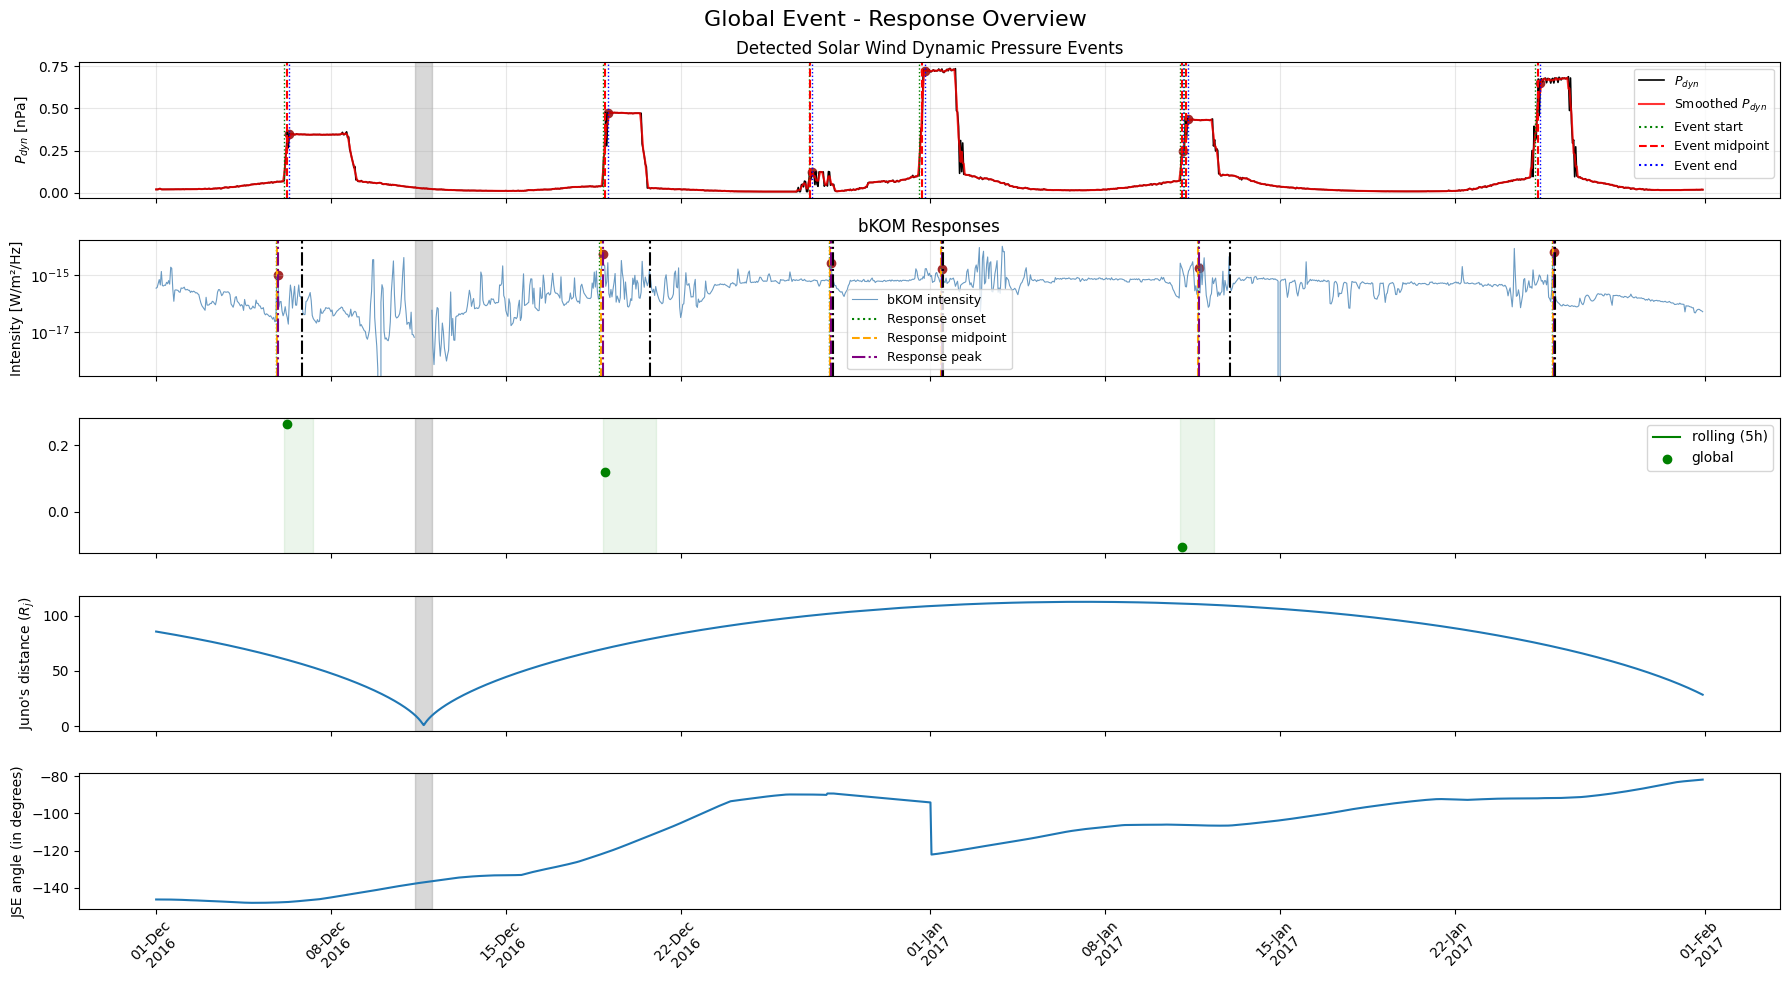

In [50]:
#%matplotlib widget
%matplotlib inline

# =============================================================================
# GLOBAL OVERVIEW PLOT
# Entire duration:
#   TOP    -> P_dyn
#   BOTTOM -> bKOM intensity (log scale)
#
# Marks:
#   - P_dyn event start
#   - P_dyn midpoint
#   - P_dyn end
#   - bKOM response base
#   - bKOM response midpoint
#   - bKOM response peak
#
# Shared x-axis
# =============================================================================

import matplotlib.dates as mdates

# -----------------------------------------------------------------------------
# FIGURE
# -----------------------------------------------------------------------------

fig, axs = plt.subplots(5, 1, figsize=(18, 10), sharex=True)

# =============================================================================
# TOP PANEL : P_dyn
# =============================================================================

axs[0].plot(P_dyn.index, P_dyn.values, color='black', lw=1.2, label=r'$P_{dyn}$')

# Optional smoothed curve
axs[0].plot(P_smooth.index, P_smooth.values, color='red', lw=1.5, alpha=0.8, label=r'Smoothed $P_{dyn}$')

# -----------------------------------------------------------------------------
# Mark ALL detected events
# -----------------------------------------------------------------------------

for i, (t_mid, row) in enumerate(df_events.iterrows()):

    t_start = row["event_start"]
    t_end   = row["event_end"]
    y_val = P_dyn.loc[t_end]

    # Start
    axs[0].axvline(t_start, color='green', linestyle=':', lw=1)

    # Midpoint
    axs[0].axvline(t_mid, color='red', linestyle='--', lw=1.5)

    # End
    axs[0].axvline(t_end, color='blue', linestyle=':', lw=1)

    axs[0].scatter(t_end, y_val, color='brown')

# Dummy handles for clean legend
axs[0].plot([], [], color='green', linestyle=':',  label='Event start')
axs[0].plot([], [], color='red',   linestyle='--', label='Event midpoint')
axs[0].plot([], [], color='blue',  linestyle=':',  label='Event end')

axs[0].set_ylabel(r'$P_{dyn}$ [nPa]')
axs[0].set_title('Detected Solar Wind Dynamic Pressure Events')
axs[0].legend(fontsize=9)
axs[0].grid(alpha=0.3)

# =============================================================================
# BOTTOM PANEL : bKOM
# =============================================================================

axs[1].plot(df_hourly1.index, df_hourly1["intensity"], color='steelblue', lw=0.8, alpha=0.8, label='bKOM intensity')

# -----------------------------------------------------------------------------
# Mark all responses
# -----------------------------------------------------------------------------

for i, (t_mid, row) in enumerate(df_combined.iterrows()):

    # response points
    t_base = row["response_base"]
    t_resp_mid = row["response_midpoint"]
    t_peak = row["response_peak"]
    y_val = df_hourly1.loc[t_peak, 'intensity']

    # baseline/onset
    axs[1].axvline(t_base, color='green', linestyle=':', lw=1)

    # midpoint
    axs[1].axvline(t_resp_mid, color='orange', linestyle='--', lw=1.5)

    # peak
    axs[1].axvline(t_peak, color='purple', linestyle='-.', lw=1.5)

    axs[1].scatter(t_peak, y_val, color='brown')
    axs[1].axvline(row["active_end"], linestyle='-.', color = 'black')

# Dummy handles
axs[1].plot([], [], color='green',  linestyle=':',  label='Response onset')
axs[1].plot([], [], color='orange', linestyle='--', label='Response midpoint')
axs[1].plot([], [], color='purple', linestyle='-.', label='Response peak')

axs[1].set_yscale('log')

axs[1].set_ylabel('Intensity [W/m²/Hz]')
axs[1].set_title('bKOM Responses')
axs[1].legend(fontsize=9)
axs[1].grid(alpha=0.3)

# =============================================================================
# X-AXIS FORMATTING
# =============================================================================

axs[1].xaxis.set_major_formatter(mdates.DateFormatter('%d-%b\n%Y'))

for event_time, row in df_final.iterrows():

    if pd.isna(row["corr_coeff"]):
        continue

    # Rolling-correlation analysis window
    t_start = event_time - pd.Timedelta(hours= row["event_duration_hr"]/2)
    t_end   = event_time + pd.Timedelta(hours= row["active_duration_hr"])

    axs[2].axvspan(t_start, t_end, color='green', alpha=0.08)
    #axs[2].plot(row["rolling_index"], row["rolling_values"], color='green', alpha=0.05)
    axs[2].scatter(event_time, row["corr_coeff"], color = 'green')

# Dummy handles for clean legend
axs[2].plot([], [], color='green',  label='rolling (5h)')
axs[2].scatter([], [], color='green', label='global')
axs[2].legend()

axs[3].plot(r_series[start:end])
axs[3].set_ylabel("Juno's distance ($R_j$)")

axs[4].plot(df_jse_subset)
axs[4].set_ylabel("JSE angle (in degrees)")

# Higlighting the unused data when JUNO was very close to the Jupiter, in our case = 10 Rj
excluded_regions = highlighted_regions(10, dist_subset, 0, time_subset)
for ax in axs:
    for (region_start, region_end) in excluded_regions:
        ax.axvspan(region_start, region_end, color='grey', alpha=0.3)

plt.xticks(rotation=45)
plt.suptitle(
    'Global Event - Response Overview',
    fontsize=16,
    y=0.98
)

plt.tight_layout()

plt.show()


(I) Adding the JSO geomtery into the problem, to divide the study into Dawn/Dusk sectors

In [ ]:
#file_jso = "/obs/kkesri/code/data/output-juno_jup_jso_2016.txt"
file_jso = '/obs/kkesri/code/ephem/juno_jup_xyz_jso_2016_2025.txt'

In [ ]:
df_jso = pd.read_csv(
    file_jso,
    comment="#",
    sep=r"\s+",
    names=["time", "x_jso", "y_jso", "z_jso"]
)

df_jso["time"] = pd.to_datetime(df_jso["time"])
df_jso = df_jso.set_index("time").sort_index()

print(df_jso.head())

                       x_jso    y_jso    z_jso
time                                          
2016-06-01 00:05:00  24.5882 -314.219  43.1244
2016-06-01 00:10:00  24.5847 -314.193  43.1216
2016-06-01 00:15:00  24.5812 -314.167  43.1188
2016-06-01 00:20:00  24.5776 -314.141  43.1160
2016-06-01 00:25:00  24.5741 -314.115  43.1133


In [ ]:
# -----------------------------------------------------------------------------
# 1. Classify every JSO timestamp first
# -----------------------------------------------------------------------------

df_jso["phi_jso_deg"] = np.degrees(
    np.arctan2(df_jso["y_jso"], df_jso["x_jso"])
)

def classify_jso_sector(phi):
    if -45 <= phi <= 45:
        return "noon/dayside"
    elif 45 < phi < 135:
        return "dusk"       # +Y
    elif -135 < phi < -45:
        return "dawn"       # -Y
    else:
        return "midnight/nightside"

df_jso["local_time_sector"] = df_jso["phi_jso_deg"].apply(classify_jso_sector)

In [ ]:
df_final["x_jso"] = np.interp(
    df_final.index.astype(np.int64),
    df_jso.index.astype(np.int64),
    df_jso["x_jso"]
)

df_final["y_jso"] = np.interp(
    df_final.index.astype(np.int64),
    df_jso.index.astype(np.int64),
    df_jso["y_jso"]
)

df_final["z_jso"] = np.interp(
    df_final.index.astype(np.int64),
    df_jso.index.astype(np.int64),
    df_jso["z_jso"]
)

df_final["phi_jso_deg"] = np.degrees(
    np.arctan2(df_final["y_jso"], df_final["x_jso"])
)

# -----------------------------------------------------------------------------
# 3. Add nearest sector label from df_jso
# -----------------------------------------------------------------------------

df_final["local_time_sector"] = (
    df_jso["local_time_sector"]
    .reindex(df_final.index, method="nearest")
)

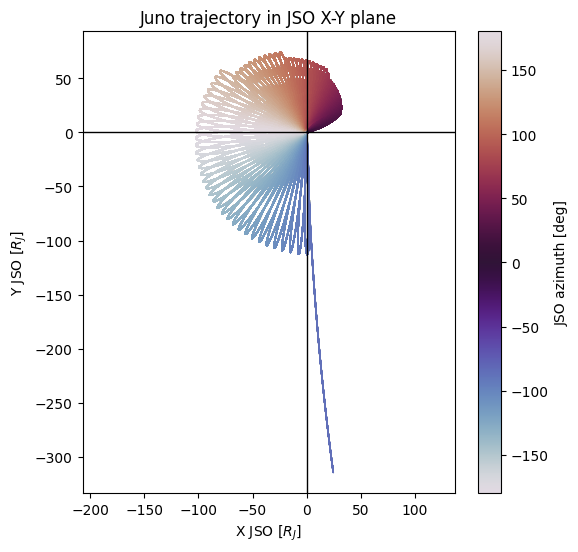

In [ ]:
plt.figure(figsize=(6,6))

plt.scatter(
    df_jso["x_jso"],
    df_jso["y_jso"],
    c=df_jso["phi_jso_deg"],
    s=0.01,
    cmap="twilight"
)

plt.axhline(0, color="k", lw=1)
plt.axvline(0, color="k", lw=1)

plt.xlabel("X JSO [$R_J$]")
plt.ylabel("Y JSO [$R_J$]")
plt.title("Juno trajectory in JSO X-Y plane")

plt.colorbar(label="JSO azimuth [deg]")
plt.axis("equal")
plt.show()

(J) Shocks Classification around event-response pairs (FRS/FFS)

In [51]:
# =============================================================================
# SHOCK PATCH DETECTION — COMPONENT BY COMPONENT
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# Parameters
# -----------------------------------------------------------------------------

PATCH_PAD_BEFORE = 5     # hours before event_start
PATCH_PAD_AFTER  = 5     # hours after plateau_end

SMOOTH_PATCH = 3          # smoothing in hours
MIN_PATCH_DURATION = 9    # minimum duration of monotonic patch in hours

# derivative thresholds: use signs first, tune later
USE_THRESHOLD = False
DERIV_QUANTILE = 0.70

In [52]:
# =============================================================================
# Helper: detect increasing/decreasing derivative patches
# =============================================================================

def detect_patches(series, quantity_name, direction="increase",
                   min_duration_hr=2, use_threshold=False,
                   deriv_quantile=0.70):

    s = series.dropna().sort_index()

    if len(s) < 5:
        return []

    ds = s.diff()

    if direction == "increase":
        if use_threshold:
            thr = ds[ds > 0].quantile(deriv_quantile)
            mask = ds > thr
        else:
            mask = ds > 0

    elif direction == "decrease":
        if use_threshold:
            thr = ds[ds < 0].quantile(1 - deriv_quantile)
            mask = ds < thr
        else:
            mask = ds < 0

    else:
        raise ValueError("direction must be 'increase' or 'decrease'")

    patches = []
    in_patch = False
    start_time = None

    for t in mask.index:

        if mask.loc[t] and not in_patch:
            in_patch = True
            start_time = t

        elif (not mask.loc[t]) and in_patch:
            end_time = t
            duration_hr = (end_time - start_time).total_seconds() / 3600

            if duration_hr >= min_duration_hr:
                value_start = s.asof(start_time)
                value_end = s.asof(end_time)
                delta = value_end - value_start

                patches.append({
                    "quantity": quantity_name,
                    "direction": direction,
                    "patch_start": start_time,
                    "patch_end": end_time,
                    "patch_midpoint": start_time + (end_time - start_time)/2,
                    "patch_duration_hr": duration_hr,
                    "value_start": value_start,
                    "value_end": value_end,
                    "delta": delta,
                    "abs_delta": abs(delta)
                })

            in_patch = False
            start_time = None

    # catch final patch
    if in_patch:
        end_time = mask.index[-1]
        duration_hr = (end_time - start_time).total_seconds() / 3600

        if duration_hr >= min_duration_hr:
            value_start = s.asof(start_time)
            value_end = s.asof(end_time)
            delta = value_end - value_start

            patches.append({
                "quantity": quantity_name,
                "direction": direction,
                "patch_start": start_time,
                "patch_end": end_time,
                "patch_midpoint": start_time + (end_time - start_time)/2,
                "patch_duration_hr": duration_hr,
                "value_start": value_start,
                "value_end": value_end,
                "delta": delta,
                "abs_delta": abs(delta)
            })

    return patches

In [53]:
# =============================================================================
# Build patch catalog around each event-response pair
# =============================================================================

all_patch_records = []

for t_event, row in df_final.iterrows():

    search_start = row["event_start"] - pd.Timedelta(hours=PATCH_PAD_BEFORE)
    search_end   = row["plateau_end"] + pd.Timedelta(hours=PATCH_PAD_AFTER)

    local = pd.DataFrame({
        "P_dyn": P_dyn.loc[search_start:search_end],
        "u_mag": u_mag.loc[search_start:search_end],
        "n_tot": n_tot.loc[search_start:search_end],
        "B_mag": B_mag.loc[search_start:search_end],
    }).dropna()

    if len(local) < 5:
        continue

    local_s = local.rolling(
        SMOOTH_PATCH,
        center=True,
        min_periods=1
    ).mean()

    event_patches = []

    # u_mag: only increasing patches for shock anchor
    event_patches += detect_patches(
        local_s["u_mag"],
        "u_mag",
        direction="increase",
        min_duration_hr=MIN_PATCH_DURATION,
        use_threshold=USE_THRESHOLD,
        deriv_quantile=DERIV_QUANTILE
    )

    # n_tot: both increase and decrease
    event_patches += detect_patches(
        local_s["n_tot"],
        "n_tot",
        direction="increase",
        min_duration_hr=MIN_PATCH_DURATION,
        use_threshold=USE_THRESHOLD,
        deriv_quantile=DERIV_QUANTILE
    )

    event_patches += detect_patches(
        local_s["n_tot"],
        "n_tot",
        direction="decrease",
        min_duration_hr=MIN_PATCH_DURATION,
        use_threshold=USE_THRESHOLD,
        deriv_quantile=DERIV_QUANTILE
    )

    # B_mag: both increase and decrease
    event_patches += detect_patches(
        local_s["B_mag"],
        "B_mag",
        direction="increase",
        min_duration_hr=MIN_PATCH_DURATION,
        use_threshold=USE_THRESHOLD,
        deriv_quantile=DERIV_QUANTILE
    )

    event_patches += detect_patches(
        local_s["B_mag"],
        "B_mag",
        direction="decrease",
        min_duration_hr=MIN_PATCH_DURATION,
        use_threshold=USE_THRESHOLD,
        deriv_quantile=DERIV_QUANTILE
    )

    # Optional: P_dyn increase patches, mostly for reference
    event_patches += detect_patches(
        local_s["P_dyn"],
        "P_dyn",
        direction="increase",
        min_duration_hr=MIN_PATCH_DURATION,
        use_threshold=USE_THRESHOLD,
        deriv_quantile=DERIV_QUANTILE
    )

    for p in event_patches:
        p["event_midpoint"] = t_event
        p["event_start"] = row["event_start"]
        p["event_end"] = row["event_end"]
        p["plateau_end"] = row["plateau_end"]

        p["delay_from_event_start_hr"] = (
            p["patch_midpoint"] - row["event_start"]
        ).total_seconds() / 3600

        all_patch_records.append(p)

df_patches = pd.DataFrame(all_patch_records)

if not df_patches.empty:
    df_patches = df_patches.set_index("event_midpoint")

print(df_patches)

                    quantity direction         patch_start  \
event_midpoint                                               
2016-12-06 05:30:00    u_mag  increase 2016-12-06 15:00:00   
2016-12-06 05:30:00    n_tot  increase 2016-12-06 03:00:00   
2016-12-06 05:30:00    B_mag  increase 2016-12-06 14:00:00   
2016-12-18 23:30:00    u_mag  increase 2016-12-18 21:00:00   
2016-12-18 23:30:00    n_tot  decrease 2016-12-19 03:00:00   
2016-12-18 23:30:00    n_tot  decrease 2016-12-20 08:00:00   
2016-12-18 23:30:00    P_dyn  increase 2016-12-18 17:00:00   
2016-12-31 16:00:00    n_tot  increase 2016-12-31 09:00:00   
2016-12-31 16:00:00    P_dyn  increase 2016-12-31 09:00:00   
2017-01-11 01:30:00    u_mag  increase 2017-01-11 10:00:00   
2017-01-11 01:30:00    P_dyn  increase 2017-01-10 21:00:00   
2017-01-25 07:30:00    B_mag  increase 2017-01-25 20:00:00   
2017-01-25 07:30:00    P_dyn  increase 2017-01-25 01:00:00   

                              patch_end      patch_midpoint  \
event_

In [54]:
# =============================================================================
# D. Inspect detected patches for ALL event timestamps
# =============================================================================

if df_patches.empty:
    print("No patches detected.")
else:
    df_patches_sorted = df_patches.sort_values(
        ["event_midpoint", "quantity", "direction", "patch_start"]
    )

    print(df_patches_sorted[
        ["quantity", "direction", "patch_start", "patch_end",
         "patch_midpoint", "patch_duration_hr", "delta",
         "delay_from_event_start_hr"]
    ])

                    quantity direction         patch_start  \
event_midpoint                                               
2016-12-06 05:30:00    B_mag  increase 2016-12-06 14:00:00   
2016-12-06 05:30:00    n_tot  increase 2016-12-06 03:00:00   
2016-12-06 05:30:00    u_mag  increase 2016-12-06 15:00:00   
2016-12-18 23:30:00    P_dyn  increase 2016-12-18 17:00:00   
2016-12-18 23:30:00    n_tot  decrease 2016-12-19 03:00:00   
2016-12-18 23:30:00    n_tot  decrease 2016-12-20 08:00:00   
2016-12-18 23:30:00    u_mag  increase 2016-12-18 21:00:00   
2016-12-31 16:00:00    P_dyn  increase 2016-12-31 09:00:00   
2016-12-31 16:00:00    n_tot  increase 2016-12-31 09:00:00   
2017-01-11 01:30:00    P_dyn  increase 2017-01-10 21:00:00   
2017-01-11 01:30:00    u_mag  increase 2017-01-11 10:00:00   
2017-01-25 07:30:00    B_mag  increase 2017-01-25 20:00:00   
2017-01-25 07:30:00    P_dyn  increase 2017-01-25 01:00:00   

                              patch_end      patch_midpoint  \
event_

In [55]:
t_event = pd.Timestamp("2016-12-06 05:30:00")

df_patches.loc[t_event].sort_values(
    ["quantity", "direction", "patch_start"]
)

,quantity,direction,patch_start,patch_end,patch_midpoint,patch_duration_hr,value_start,value_end,delta,abs_delta,event_start,event_end,plateau_end,delay_from_event_start_hr
event_midpoint,,,,,,,,,,,,,,
2016-12-06 05:30:00,B_mag,increase,2016-12-06 14:00:00,2016-12-06 23:00:00,2016-12-06 18:30:00,9.0,0.2322,1.004467,0.772267,0.772267,2016-12-06 03:00:00,2016-12-06 08:00:00,2016-12-08 19:00:00,15.5
2016-12-06 05:30:00,n_tot,increase,2016-12-06 03:00:00,2016-12-06 12:00:00,2016-12-06 07:30:00,9.0,0.3552,0.950633,0.595433,0.595433,2016-12-06 03:00:00,2016-12-06 08:00:00,2016-12-08 19:00:00,4.5
2016-12-06 05:30:00,u_mag,increase,2016-12-06 15:00:00,2016-12-07 00:00:00,2016-12-06 19:30:00,9.0,399.3740,460.571600,61.197600,61.197600,2016-12-06 03:00:00,2016-12-06 08:00:00,2016-12-08 19:00:00,16.5


In [56]:
# =============================================================================
# Match n/B patches around u_mag increase patches
# =============================================================================

MATCH_TOL_HOURS = 12

shock_match_records = []

for t_event in df_patches.index.unique():

    patches = df_patches.loc[[t_event]].copy()

    u_patches = patches[
        (patches["quantity"] == "u_mag") &
        (patches["direction"] == "increase")
    ]

    for _, u_patch in u_patches.iterrows():

        u_time = u_patch["patch_midpoint"]

        nearby = patches[
            np.abs(
                (patches["patch_midpoint"] - u_time)
                .dt.total_seconds() / 3600
            ) <= MATCH_TOL_HOURS
        ]

        n_inc = nearby[
            (nearby["quantity"] == "n_tot") &
            (nearby["direction"] == "increase")
        ]

        n_dec = nearby[
            (nearby["quantity"] == "n_tot") &
            (nearby["direction"] == "decrease")
        ]

        B_inc = nearby[
            (nearby["quantity"] == "B_mag") &
            (nearby["direction"] == "increase")
        ]

        B_dec = nearby[
            (nearby["quantity"] == "B_mag") &
            (nearby["direction"] == "decrease")
        ]

        has_ffs = (len(n_inc) > 0) and (len(B_inc) > 0)
        has_frs = (len(n_dec) > 0) and (len(B_dec) > 0)

        if has_ffs and has_frs:
            shock_type = "FFS_and_FRS_candidates"
        elif has_ffs:
            shock_type = "FFS_candidate_no_T"
        elif has_frs:
            shock_type = "FRS_candidate_no_T"
        else:
            shock_type = "u_jump_only"

        shock_match_records.append({
            "event_midpoint": t_event,
            "u_patch_start": u_patch["patch_start"],
            "u_patch_end": u_patch["patch_end"],
            "u_patch_midpoint": u_time,
            "u_delta": u_patch["delta"],

            "shock_type": shock_type,

            "n_inc_count": len(n_inc),
            "n_dec_count": len(n_dec),
            "B_inc_count": len(B_inc),
            "B_dec_count": len(B_dec),

            "matched_patch_table": nearby
        })

df_shock_matches = pd.DataFrame(shock_match_records)

if not df_shock_matches.empty:
    df_shock_matches = df_shock_matches.set_index("event_midpoint")

print(df_shock_matches[
    ["shock_type", "u_patch_midpoint",
     "n_inc_count", "n_dec_count", "B_inc_count", "B_dec_count"]
])

                             shock_type    u_patch_midpoint  n_inc_count  \
event_midpoint                                                             
2016-12-06 05:30:00  FFS_candidate_no_T 2016-12-06 19:30:00            1   
2016-12-18 23:30:00         u_jump_only 2016-12-19 02:30:00            0   
2017-01-11 01:30:00         u_jump_only 2017-01-11 16:00:00            0   

                     n_dec_count  B_inc_count  B_dec_count  
event_midpoint                                              
2016-12-06 05:30:00            0            1            0  
2016-12-18 23:30:00            1            0            0  
2017-01-11 01:30:00            0            0            0  


(K) Including solar cycle into the picture!

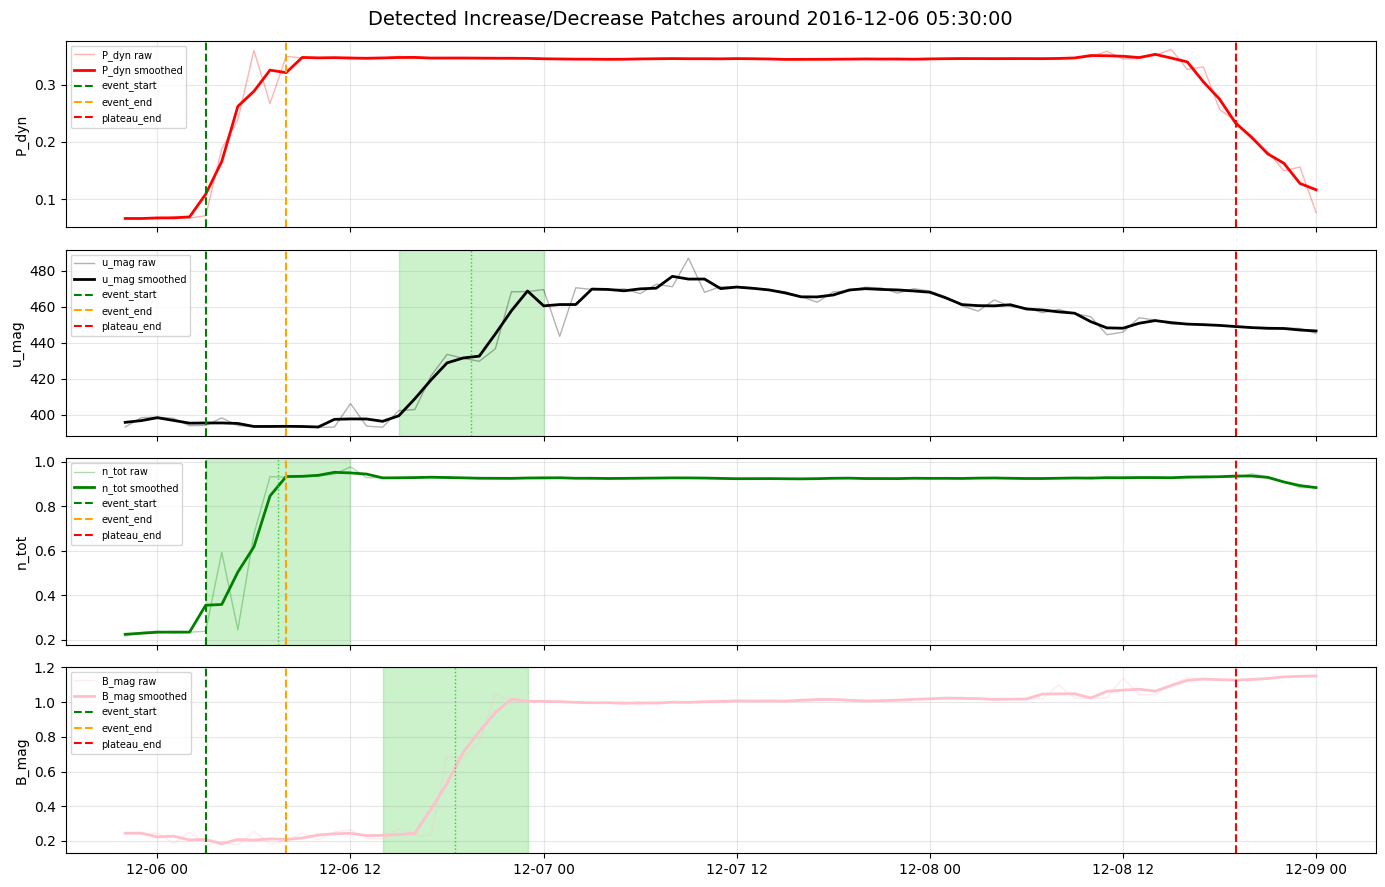

In [57]:
# =============================================================================
# VISUALIZE PATCHES FOR ONE EVENT
# =============================================================================

t_event = pd.Timestamp("2016-12-06 05:30:00")

row = df_final.loc[t_event]

plot_start = row["event_start"] - pd.Timedelta(hours=PATCH_PAD_BEFORE)
plot_end   = row["plateau_end"] + pd.Timedelta(hours=PATCH_PAD_AFTER)

local = pd.DataFrame({
    "P_dyn": P_dyn.loc[plot_start:plot_end],
    "u_mag": u_mag.loc[plot_start:plot_end],
    "n_tot": n_tot.loc[plot_start:plot_end],
    "B_mag": B_mag.loc[plot_start:plot_end],
}).dropna()

local_s = local.rolling(
    SMOOTH_PATCH,
    center=True,
    min_periods=1
).mean()

patches_event = df_patches.loc[[t_event]].copy()

fig, axs = plt.subplots(
    4, 1,
    figsize=(14, 9),
    sharex=True
)

plot_info = [
    ("P_dyn", "P_dyn", "red"),
    ("u_mag", "u_mag", "black"),
    ("n_tot", "n_tot", "green"),
    ("B_mag", "B_mag", "pink"),
]

for ax, (col, label, color) in zip(axs, plot_info):

    ax.plot(
        local.index,
        local[col],
        color=color,
        alpha=0.3,
        lw=1,
        label=f"{label} raw"
    )

    ax.plot(
        local_s.index,
        local_s[col],
        color=color,
        lw=2,
        label=f"{label} smoothed"
    )

    # Event markers
    ax.axvline(row["event_start"], color="green", linestyle="--", lw=1.5, label="event_start")
    ax.axvline(row["event_end"], color="orange", linestyle="--", lw=1.5, label="event_end")
    ax.axvline(row["plateau_end"], color="red", linestyle="--", lw=1.5, label="plateau_end")

    # Patches for this quantity
    sub = patches_event[patches_event["quantity"] == col]

    for _, p in sub.iterrows():

        if p["direction"] == "increase":
            patch_color = "limegreen"
            alpha = 0.25
        else:
            patch_color = "tomato"
            alpha = 0.25

        ax.axvspan(
            p["patch_start"],
            p["patch_end"],
            color=patch_color,
            alpha=alpha
        )

        ax.axvline(
            p["patch_midpoint"],
            color=patch_color,
            linestyle=":",
            lw=1
        )

    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="upper left")

plt.suptitle(
    f"Detected Increase/Decrease Patches around {t_event}",
    fontsize=14
)

plt.tight_layout()
plt.show()

# Restarting everything

(A) Data representation

In [86]:
# =============================================================================
# PART A — LOAD, CLEAN, RESAMPLE, AND VISUALIZE RAW DATA
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# A.0 Analysis interval
# -----------------------------------------------------------------------------

start = pd.Timestamp("2016-12-01 00:00:00")
end   = pd.Timestamp("2017-01-31 22:00:00")

In [87]:
# -----------------------------------------------------------------------------
# A.1 Build Juno bKOM + distance dataframe
# -----------------------------------------------------------------------------

df_juno_min = pd.DataFrame({
    "time": pd.to_datetime(time_over_year_sec, unit="s"),
    "intensity_raw": normalized_integrated_intensity_bKOM,
    "dist_RJ": obdist
})

df_juno_min = df_juno_min.set_index("time").sort_index()

# Replace non-physical intensity values with NaN
df_juno_min["intensity"] = df_juno_min["intensity_raw"].where(
    df_juno_min["intensity_raw"] > 0,
    np.nan
)

# Optional: interpolate only small gaps
# This avoids inventing long missing intervals.
df_juno_min["intensity_interp"] = (
    df_juno_min["intensity"]
    .interpolate(method="time", limit=5)
)

# Distance should be smooth, but keep separately
df_juno_min["dist_interp"] = (
    df_juno_min["dist_RJ"]
    .interpolate(method="time")
)

# Slice minute-level data
df_juno_min_subset = df_juno_min.loc[start:end].copy()

print(df_juno_min.shape)

(2623680, 5)


In [88]:
# -----------------------------------------------------------------------------
# A.2 Hourly resampling
# -----------------------------------------------------------------------------

df_hourly = pd.DataFrame()

df_hourly["intensity"] = (
    df_juno_min["intensity_interp"]
    .resample("1H")
    .mean()
)

df_hourly["dist"] = (
    df_juno_min["dist_interp"]
    .resample("1H")
    .mean()
)

df_hourly1 = df_hourly.loc[start:end].copy()

print("\nHourly Juno subset:")
print(df_hourly1.shape)

print("\nCadence check:")
print(df_hourly1.index.to_series().diff().value_counts().head())


Hourly Juno subset:
(1487, 2)

Cadence check:
time
0 days 01:00:00    1486
Name: count, dtype: int64


In [89]:
# -----------------------------------------------------------------------------
# A.3 Data-quality checks
# -----------------------------------------------------------------------------

raw_subset = df_juno_min.loc[start:end, "intensity_raw"]
clean_subset = df_juno_min.loc[start:end, "intensity"]
interp_subset = df_juno_min.loc[start:end, "intensity_interp"]

n_total = len(raw_subset)
n_zero = (raw_subset == 0).sum()
n_negative = (raw_subset < 0).sum()
n_nan_clean = clean_subset.isna().sum()
n_nan_interp = interp_subset.isna().sum()

print("\n--- Juno bKOM quality check ---")
print(f"Total minute samples      : {n_total}")
print(f"Zero samples              : {n_zero}")
print(f"Negative samples          : {n_negative}")
print(f"NaN after zero removal    : {n_nan_clean}")
print(f"NaN after interpolation   : {n_nan_interp}")
print(f"Zero fraction             : {100*n_zero/n_total:.2f}%")


--- Juno bKOM quality check ---
Total minute samples      : 92040
Zero samples              : 214
Negative samples          : 0
NaN after zero removal    : 1211
NaN after interpolation   : 1196
Zero fraction             : 0.23%


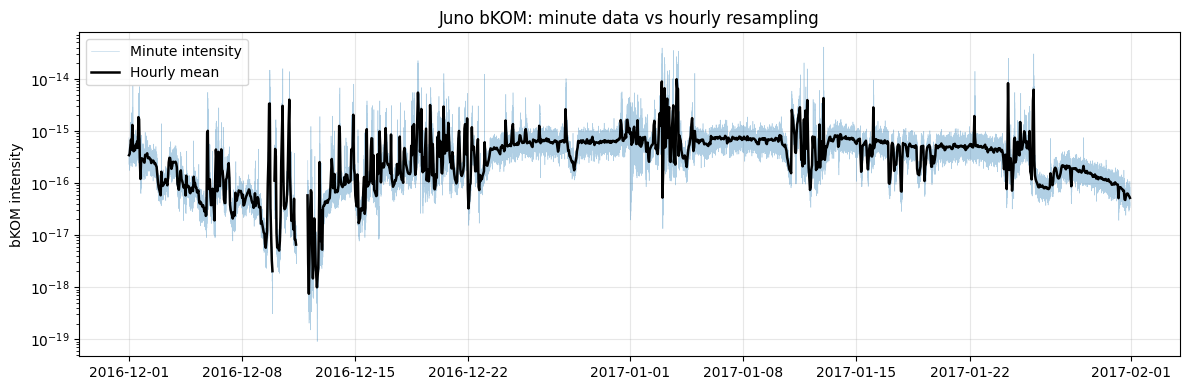

In [90]:
# -----------------------------------------------------------------------------
# A.4 Resampling sanity plot
# -----------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    df_juno_min_subset.index,
    df_juno_min_subset["intensity"],
    lw=0.4,
    alpha=0.35,
    label="Minute intensity"
)

ax.plot(
    df_hourly1.index,
    df_hourly1["intensity"],
    lw=1.8,
    color="black",
    label="Hourly mean"
)

ax.set_yscale("log")
ax.set_ylabel("bKOM intensity")
ax.set_title("Juno bKOM: minute data vs hourly resampling")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [91]:
# -----------------------------------------------------------------------------
# A.5 MMESH variables
# -----------------------------------------------------------------------------

P_dyn = MMESH_slicing(start, end, "P_dyn")
B_mag = MMESH_slicing(start, end, "B_mag")
u_mag = MMESH_slicing(start, end, "u_mag")
n_tot = MMESH_slicing(start, end, "n_tot")

timestamps = MMESH_slicing(start, end, "1").index

print("\n--- MMESH cadence check ---")
print(P_dyn.index.to_series().diff().value_counts().head())

print("\nMMESH ranges:")
print("P_dyn:", P_dyn.min(), P_dyn.max())
print("B_mag:", B_mag.min(), B_mag.max())
print("u_mag:", u_mag.min(), u_mag.max())
print("n_tot:", n_tot.min(), n_tot.max())


--- MMESH cadence check ---
datetime
0 days 01:00:00    1486
Name: count, dtype: int64

MMESH ranges:
P_dyn: 0.0063 0.7368
B_mag: 0.1353 2.6441
u_mag: 379.2906 557.2697
n_tot: 0.0218 2.172


In [ ]:
# -----------------------------------------------------------------------------
# A.6 Alignment check
# -----------------------------------------------------------------------------

df_align_check = pd.concat(
    [
        df_hourly1["intensity"],
        P_dyn.rename("P_dyn"),
        B_mag.rename("B_mag"),
        u_mag.rename("u_mag"),
        n_tot.rename("n_tot")
    ],plt.scatter(
    df_jso["x_jso"],
    df_jso["y_jso"],
    c=df_jso["phi_jso_deg"],
    s=0.01,
    cmap="twilight"
)

plt.axhline(0, color="k", lw=1)
plt.axvline(0, color="k", lw=1)

plt.xlabel("X JSO [$R_J$]")
plt.ylabel("Y JSO [$R_J$]")
plt.title("Juno trajectory in JSO X-Y plane")

plt.colorbar(label="JSO azimuth [deg]")
plt.axis("equal")
plt.show()
)
    axis=1
)

print("\n--- Alignment check ---")
print(df_align_check.shape)


--- Alignment check ---
(1487, 5)


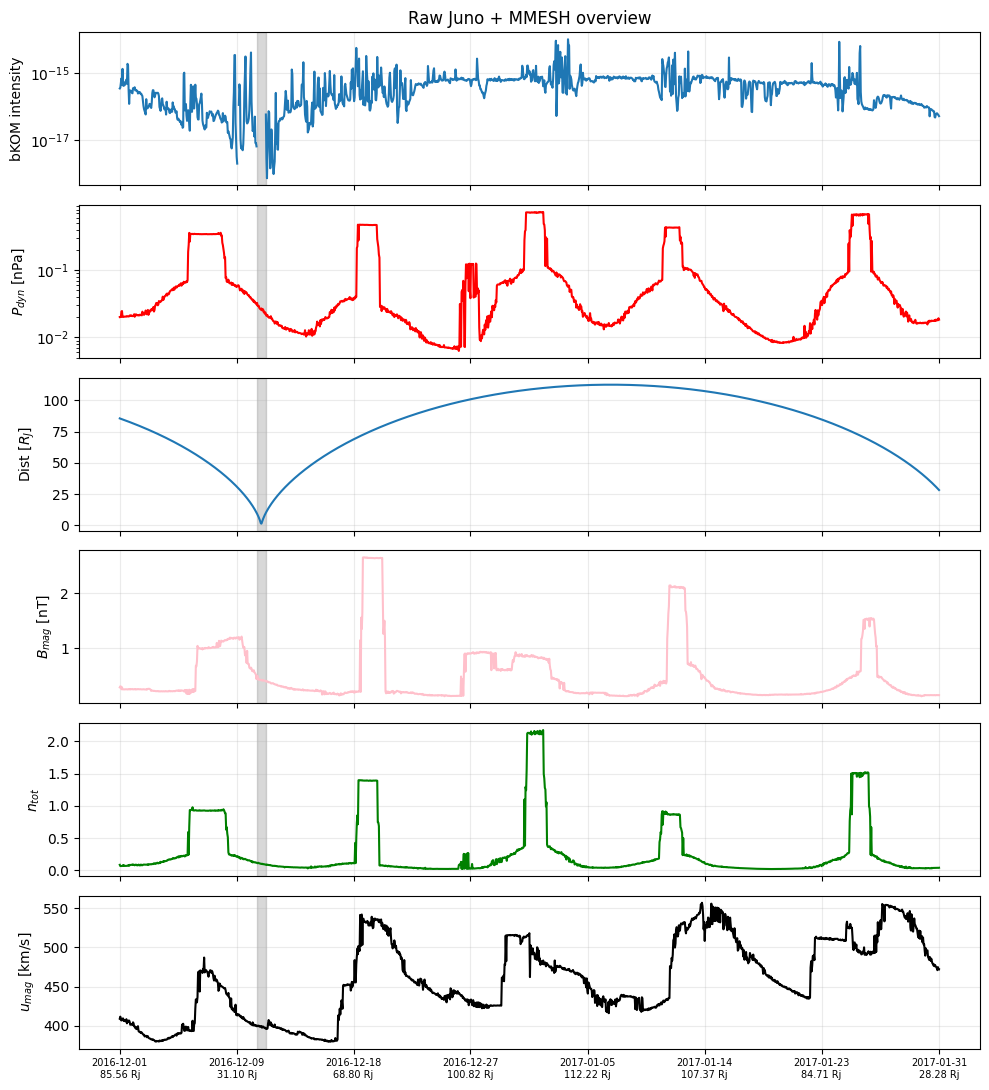

In [93]:
# -----------------------------------------------------------------------------
# A.7 Raw overview plot
# -----------------------------------------------------------------------------

time_subset = df_hourly1.index
intensity_subset = df_hourly1["intensity"]
dist_subset = df_hourly1["dist"]

x_marker = ticks(time_subset, dist_subset)

fig, axs = plt.subplots(
    6, 1,
    sharex=True,
    figsize=(10, 11)
)

# bKOM
axs[0].plot(time_subset, intensity_subset, color="tab:blue")
axs[0].set_yscale("log")
axs[0].set_ylabel("bKOM intensity")
axs[0].set_title("Raw Juno + MMESH overview")

# P_dyn
axs[1].plot(P_dyn.index, P_dyn, color="red")
axs[1].set_ylabel(r"$P_{dyn}$ [nPa]")
axs[1].set_yscale("log")

# distance
axs[2].plot(time_subset, dist_subset, color="tab:blue")
axs[2].set_ylabel(r"Dist [$R_J$]")

# B_mag
axs[3].plot(B_mag.index, B_mag, color="pink")
axs[3].set_ylabel(r"$B_{mag}$ [nT]")

# n_tot
axs[4].plot(n_tot.index, n_tot, color="green")
axs[4].set_ylabel(r"$n_{tot}$")

# u_mag
axs[5].plot(u_mag.index, u_mag, color="black")
axs[5].set_ylabel(r"$u_{mag}$ [km/s]")

# Exclude close Juno regions
excluded_regions = highlighted_regions(
    10,
    dist_subset.values,
    0,
    time_subset
)

for ax in axs:
    for region_start, region_end in excluded_regions:
        ax.axvspan(region_start, region_end, color="grey", alpha=0.3)

    ax.grid(alpha=0.25)

plt.xticks(x_marker[0], x_marker[1], size=7, rotation=0)
plt.tight_layout()
plt.show()

(B) Declaring the Variables and including the Jupiter-sun-earth angles

In [94]:
# -----------------------------------------------------------------------------
# PARAMETERS (keep these explicit so you can tune easily)
# -----------------------------------------------------------------------------

# -- Parameters for part A --
SMOOTH_P = 3                  # smoothing for P_dyn
DERIV_THRESHOLD = 0.02        # threshold for sharp rise dP/dt (tuneable!)
PLATEAU_FRACTION = 0.8        # for P_dyn plateau hunt
MIN_EVENT_DURATION = 3        # minimum duration (hours)

# -- Parameters for part B -- 
# Layer 1: response-search window
BKOM_SEARCH_WINDOW = 36       # ±24 h around event midpoint

In [95]:
path = '/obs/kkesri/code/data/output-jup_sw_da_2016.txt'

def JSE():
    data_file = numpy.loadtxt(path, dtype="str")
    dates = amdadate_to_datetime(data_file[:, 0][:])
    angles = data_file[:, 1].astype(float)
    return (dates, angles)

JSE_data = JSE()
jse_dates, jse_angles = JSE_data

df_jse = pd.DataFrame({
    "time": pd.to_datetime(jse_dates),
    "angle": jse_angles
})
df_jse.set_index("time", inplace=True)

# Option A: Replace outliers with NaN (keeps index intact, good for plotting) 
# df_jse["angle"] = df_jse["angle"].where(df_jse["angle"].between(-180, 180), other=numpy.nan)

# Option B: Replace with NaN then interpolate (smoothly fills gaps) 
df_jse["angle"] = df_jse["angle"].where(df_jse["angle"].between(-180, 180), other=numpy.nan)
df_jse["angle"] = df_jse["angle"].interpolate(method="time")

jse_angles = df_jse['angle']; jse_dates = df_jse.index

df_jse.index= pd.to_datetime(df_jse.index)
df_jse_subset= df_jse[start:end]
#print(df_jse_subset)

(C) Identifying the event in MMESH P_dyn timeseries

In [96]:
# =============================================================================
# PART C — DETECT SOLAR-WIND PRESSURE FORCING INTERVALS
# =============================================================================

P_smooth = P_dyn.rolling(SMOOTH_P, center=True, min_periods=1).mean()
dP = P_smooth.diff()
rising = dP > DERIV_THRESHOLD

forcing_records = []
in_forcing = False
forcing_start = None

for t in rising.index:

    if rising.loc[t] and not in_forcing:
        in_forcing = True
        forcing_start = t

    elif (not rising.loc[t]) and in_forcing:

        forcing_rise_end = t

        forcing_rise_duration_hr = (
            forcing_rise_end - forcing_start
        ).total_seconds() / 3600

        if forcing_rise_duration_hr >= MIN_EVENT_DURATION:

            rise_end_value = P_smooth.asof(forcing_rise_end)
            plateau_threshold = PLATEAU_FRACTION * rise_end_value

            after_rise = P_smooth.loc[forcing_rise_end:]
            forcing_plateau_end = after_rise.index[-1]

            for tt, val in after_rise.items():
                if val < plateau_threshold:
                    forcing_plateau_end = tt
                    break

            forcing_window = P_smooth.loc[
                forcing_start:forcing_plateau_end
            ]

            forcing_peak_time = forcing_window.idxmax()
            forcing_peak_value = forcing_window.max()

            forcing_midpoint = (
                forcing_start
                + (forcing_rise_end - forcing_start) / 2
            )

            forcing_plateau_duration_hr = (
                forcing_plateau_end - forcing_rise_end
            ).total_seconds() / 3600

            forcing_duration_hr = (
                forcing_plateau_end - forcing_start
            ).total_seconds() / 3600

            forcing_records.append({
                "forcing_start": forcing_start,
                "forcing_rise_end": forcing_rise_end,
                "forcing_midpoint": forcing_midpoint,
                "forcing_peak_time": forcing_peak_time,
                "forcing_peak_value": forcing_peak_value,
                "forcing_plateau_end": forcing_plateau_end,
                "forcing_rise_duration_hr": forcing_rise_duration_hr,
                "forcing_plateau_duration_hr": forcing_plateau_duration_hr,
                "forcing_duration_hr": forcing_duration_hr,
                "plateau_threshold": plateau_threshold,
                "rise_end_value": rise_end_value,
            })

        in_forcing = False

df_forcing = pd.DataFrame(forcing_records)

if not df_forcing.empty:
    df_forcing = df_forcing.set_index("forcing_midpoint")

print(df_forcing.shape)

(7, 10)


Visual check for the identified events

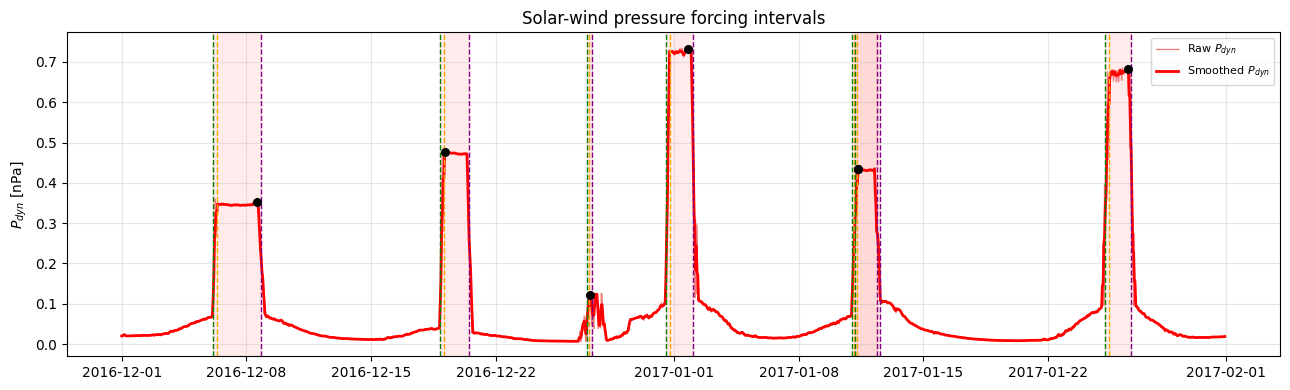

In [ ]:
# =============================================================================
# PART D.1 — VISUAL CHECK
# =============================================================================

fig, ax = plt.subplots(figsize=(13, 4))

ax.plot(P_dyn.index, P_dyn, color="lightcoral", lw=1, label="Raw $P_{dyn}$")
ax.plot(P_smooth.index, P_smooth, color="red", lw=2, label="Smoothed $P_{dyn}$")

for t_mid, row in df_forcing.iterrows():

    ax.axvspan(row["forcing_start"], row["forcing_plateau_end"], color="red", alpha=0.08)
    ax.axvline(row["forcing_start"], color="green", linestyle="--", lw=1)
    ax.axvline(row["forcing_rise_end"], color="orange", linestyle="--", lw=1)
    ax.axvline(row["forcing_plateau_end"], color="purple", linestyle="--", lw=1)
    ax.scatter(row["forcing_peak_time"], row["forcing_peak_value"], color="black", s=30, zorder=5)

ax.set_ylabel(r"$P_{dyn}$ [nPa]")
ax.set_title("Solar-wind pressure forcing intervals")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

plt.tight_layout()plt.scatter(
    df_jso["x_jso"],
    df_jso["y_jso"],
    c=df_jso["phi_jso_deg"],
    s=0.01,
    cmap="twilight"
)

plt.axhline(0, color="k", lw=1)
plt.axvline(0, color="k", lw=1)

plt.xlabel("X JSO [$R_J$]")
plt.ylabel("Y JSO [$R_J$]")
plt.title("Juno trajectory in JSO X-Y plane")

plt.colorbar(label="JSO azimuth [deg]")
plt.axis("equal")
plt.show()
)
plt.show()

(D) Finding the response, lag and active duration 

In [ ]:
# =============================================================================
# D. FIND bKOM RESPONSE + GAUSSIAN ENVELOPE ACTIVE DURATION
# =============================================================================

from scipy.optimize import curve_fit

# -----------------------------------------------------------------------------
# Parameters
# -----------------------------------------------------------------------------

ENVELOPE_WINDOW = 20
ENVELOPE_QUANTILE = 0.90

FIT_WINDOW_BEFORE = 70
FIT_WINDOW_AFTER  = 70

MIN_FIT_POINTS = 15

# Gaussian center allowed within ± this many hours of burst peak
T0_BOUND = 36

# -----------------------------------------------------------------------------
# Gaussian model
# -----------------------------------------------------------------------------

def gaussian_pulse(t, baseline, amp, t0, sigma_t):
    return baseline + amp * np.exp(-0.5 * ((t - t0) / sigma_t)**2)


# -----------------------------------------------------------------------------
# Main loop
# -----------------------------------------------------------------------------

bkom_results = []
used_response_times = []

for t_forcing in df_forcing.index:

    # =========================================================================
    # LAYER 1: FIND CANDIDATE bKOM BURST WITHIN ±24 h OF FORCING MIDPOINT
    # =========================================================================

    response_window = df_hourly.loc[
        t_forcing - pd.Timedelta(hours=BKOM_SEARCH_WINDOW):
        t_forcing + pd.Timedelta(hours=BKOM_SEARCH_WINDOW),
        "intensity"
    ].dropna()

    if len(response_window) < 5:
        continue

    logI_response = np.log10(response_window[response_window > 0]).dropna()

    if len(logI_response) < 5:
        continue

    dlogI = logI_response.diff()
    rising = dlogI > 0

    segments = []
    current_segment = []

    for t in rising.index:

        if rising.loc[t]:
            current_segment.append(t)

        else:
            if len(current_segment) > 1:
                segments.append(current_segment)

            current_segment = []

    if len(current_segment) > 1:
        segments.append(current_segment)

    if len(segments) == 0:
        continue

    best_jump = -np.inf
    best_segment = None

    for seg in segments:

        t_start = seg[0]
        t_end = seg[-1]

        jump = logI_response.loc[t_end] - logI_response.loc[t_start]

        if jump > best_jump:
            best_jump = jump
            best_segment = (t_start, t_end)

    burst_base, burst_peak = best_segment

    baseline_log = logI_response.loc[burst_base]
    peak_log = logI_response.loc[burst_peak]

    jump_log = peak_log - baseline_log
    response_ratio = 10**jump_log

    burst_midpoint = burst_base + (burst_peak - burst_base) / 2

    burst_duration_hr = (
        burst_peak - burst_base
    ).total_seconds() / 3600

    # Avoid assigning same response burst to nearby forcing events
    if any(
        abs((burst_midpoint - used).total_seconds() / 3600) < 6
        for used in used_response_times
    ):
        continue

    used_response_times.append(burst_midpoint)
    lag_hours_peak = (burst_peak - t_forcing).total_seconds() / 3600

    # =========================================================================
    # LAYER 2: FIT GAUSSIAN TO UPPER ENVELOPE AROUND BURST
    # =========================================================================

    fit_window = df_hourly.loc[
        burst_peak - pd.Timedelta(hours=FIT_WINDOW_BEFORE):
        burst_peak + pd.Timedelta(hours=FIT_WINDOW_AFTER),
        "intensity"
    ].dropna()

    logI_fit = np.log10(fit_window[fit_window > 0]).dropna()

    if len(logI_fit) < MIN_FIT_POINTS:

        fit_success = False

        active_start = burst_base
        active_end = burst_peak
        active_duration_hr = burst_duration_hr

        fit_baseline = np.nan
        fit_amp = np.nan
        fit_t0 = np.nan
        fit_sigma_hr = np.nan
        fit_fwhm_hr = np.nan
        energy_proxy = np.nan

        active_start_1sigma = pd.NaT
        active_end_1sigma = pd.NaT
        active_duration_1sigma_hr = np.nan

        active_start_2sigma = pd.NaT
        active_end_2sigma = pd.NaT
        active_duration_2sigma_hr = np.nan

        active_start_3sigma = pd.NaT
        active_end_3sigma = pd.NaT
        active_duration_3sigma_hr = np.nan

    else:

        envelope = (
            logI_fit
            .rolling(
                ENVELOPE_WINDOW,
                center=True,
                min_periods=1
            )
            .quantile(ENVELOPE_QUANTILE)
        )

        t_hours = (
            envelope.index - burst_peak
        ).total_seconds() / 3600

        y = envelope.values

        # ---------------------------------------------------------------------
        # Improved initial guesses
        # ---------------------------------------------------------------------

        baseline_guess = np.nanpercentile(y, 20)
        amp_guess = np.nanmax(y) - baseline_guess

        if amp_guess <= 0:
            amp_guess = 0.1

        t0_guess = t_hours[np.nanargmax(y)]
        sigma_guess = 18.0

        p0 = [
            baseline_guess,
            amp_guess,
            t0_guess,
            sigma_guess
        ]

        bounds = (
            [
                np.nanmin(y) - 1.0,
                0.0,
                -T0_BOUND,
                2.0
            ],
            [
                np.nanmax(y) + 1.0,
                5.0,
                T0_BOUND,
                FIT_WINDOW_BEFORE + FIT_WINDOW_AFTER
            ]
        )

        try:

            popt, pcov = curve_fit(
                gaussian_pulse,
                t_hours,
                y,
                p0=p0,
                bounds=bounds,
                maxfev=20000
            )

            fit_baseline, fit_amp, fit_t0, fit_sigma_hr = popt

            fit_fwhm_hr = 2.355 * fit_sigma_hr

            # -------------------------------------------------------------
            # Active intervals from Gaussian width
            # -------------------------------------------------------------

            active_start_1sigma = burst_peak + pd.Timedelta(
                hours=fit_t0 - fit_sigma_hr
            )
            active_end_1sigma = burst_peak + pd.Timedelta(
                hours=fit_t0 + fit_sigma_hr
            )
            active_duration_1sigma_hr = 2 * fit_sigma_hr

            active_start_2sigma = burst_peak + pd.Timedelta(
                hours=fit_t0 - 2 * fit_sigma_hr
            )
            active_end_2sigma = burst_peak + pd.Timedelta(
                hours=fit_t0 + 2 * fit_sigma_hr
            )
            active_duration_2sigma_hr = 4 * fit_sigma_hr

            active_start_3sigma = burst_peak + pd.Timedelta(
                hours=fit_t0 - 3 * fit_sigma_hr
            )
            active_end_3sigma = burst_peak + pd.Timedelta(
                hours=fit_t0 + 3 * fit_sigma_hr
            )
            active_duration_3sigma_hr = 6 * fit_sigma_hr

            # Main definition: ±2 sigma
            active_start = active_start_2sigma
            active_end = active_end_2sigma
            active_duration_hr = active_duration_2sigma_hr

            energy_proxy = fit_amp * fit_sigma_hr * np.sqrt(2 * np.pi)

            fit_success = True

        except Exception:

            fit_success = False

            active_start = burst_base
            active_end = burst_peak
            active_duration_hr = burst_duration_hr

            fit_baseline = np.nan
            fit_amp = np.nan
            fit_t0 = np.nan
            fit_sigma_hr = np.nan
            fit_fwhm_hr = np.nan
            energy_proxy = np.nan

            active_start_1sigma = pd.NaT
            active_end_1sigma = pd.NaT
            active_duration_1sigma_hr = np.nan

            active_start_2sigma = pd.NaT
            active_end_2sigma = pd.NaT
            active_duration_2sigma_hr = np.nan

            active_start_3sigma = pd.NaT
            active_end_3sigma = pd.NaT
            active_duration_3sigma_hr = np.nan

    # =========================================================================
    # STORE
    # =========================================================================

    bkom_results.append({
        "forcing_midpoint": t_forcing,

        # burst quantities
        "burst_base": burst_base,
        "burst_peak": burst_peak,
        "burst_midpoint": burst_midpoint,
        "burst_duration_hr": burst_duration_hr,

        # response strength
        "baseline_log": baseline_log,
        "peak_log": peak_log,
        "jump_log": jump_log,
        "response_ratio": response_ratio,
        #"lag_hours_peak":lag_hours_peak,

        # main active interval definition: ±2σ
        "active_start": active_start,
        "active_end": active_end,
        "active_duration_hr": active_duration_hr,

        # fit parameters
        "fit_success": fit_success,
        "fit_baseline_log": fit_baseline,
        "fit_amp_log": fit_amp,
        "fit_t0_hr": fit_t0,
        "fit_sigma_hr": fit_sigma_hr,
        "fit_fwhm_hr": fit_fwhm_hr,
        "energy_proxy": energy_proxy,

        # sigma-width alternatives
        "active_start_1sigma": active_start_1sigma,
        "active_end_1sigma": active_end_1sigma,
        "active_duration_1sigma_hr": active_duration_1sigma_hr,

        "active_start_2sigma": active_start_2sigma,
        "active_end_2sigma": active_end_2sigma,
        "active_duration_2sigma_hr": active_duration_2sigma_hr,

        "active_start_3sigma": active_start_3sigma,
        "active_end_3sigma": active_end_3sigma,
        "active_duration_3sigma_hr": active_duration_3sigma_hr,
    })


df_bkom = pd.DataFrame(bkom_results)

if not df_bkom.empty:
    df_bkom = df_bkom.set_index("forcing_midpoint")



(E) Joining the bKOM and MMESH event-response pairs

In [110]:
# =============================================================================
# PART E — JOIN FORCING + BKOM RESPONSE
# =============================================================================

df_combined = df_forcing.join(df_bkom, how="inner")

lag = (df_combined['forcing_peak_time'] - df_combined["burst_peak"])
print(lag)


print(df_combined["forcing_peak_time"], df_combined["burst_peak"])

forcing_midpoint
2016-12-06 05:30:00     2 days 17:00:00
2016-12-18 23:30:00     0 days 06:00:00
2016-12-27 04:30:00   -1 days +07:00:00
2016-12-31 16:00:00     0 days 08:00:00
2017-01-11 01:30:00   -1 days +01:00:00
2017-01-25 07:30:00     2 days 03:00:00
dtype: timedelta64[ns]
forcing_midpoint
2016-12-06 05:30:00   2016-12-08 14:00:00
2016-12-18 23:30:00   2016-12-19 03:00:00
2016-12-27 04:30:00   2016-12-27 07:00:00
2016-12-31 16:00:00   2017-01-01 19:00:00
2017-01-11 01:30:00   2017-01-11 08:00:00
2017-01-25 07:30:00   2017-01-26 12:00:00
Name: forcing_peak_time, dtype: datetime64[ns] forcing_midpoint
2016-12-06 05:30:00   2016-12-05 21:00:00
2016-12-18 23:30:00   2016-12-18 21:00:00
2016-12-27 04:30:00   2016-12-28 00:00:00
2016-12-31 16:00:00   2017-01-01 11:00:00
2017-01-11 01:30:00   2017-01-12 07:00:00
2017-01-25 07:30:00   2017-01-24 09:00:00
Name: burst_peak, dtype: datetime64[ns]


In [100]:
df_combined["lag_hours_peak"]

forcing_midpoint
2016-12-06 05:30:00    -8.5
2016-12-18 23:30:00    -2.5
2016-12-27 04:30:00    19.5
2016-12-31 16:00:00    19.0
2017-01-11 01:30:00    29.5
2017-01-25 07:30:00   -22.5
Name: lag_hours_peak, dtype: float64

(F) Overlap ratio between P_dyn and bKOM

In [67]:
# =============================================================================
# PART F — COUPLING BETWEEN P_dyn AND MEASURED bKOM UPPER ENVELOPE
# =============================================================================

from scipy.stats import spearmanr

In [68]:
# -----------------------------------------------------------------------------
# Helper functions
# -----------------------------------------------------------------------------

def minmax_series(s):
    s = s.dropna()

    if len(s) < 3:
        return s * np.nan

    s_min = s.min()
    s_max = s.max()

    if s_max == s_min:
        return s * np.nan

    return (s - s_min) / (s_max - s_min)


def zscore_series(s):
    s = s.dropna()

    if len(s) < 3:
        return s * np.nan

    s_std = s.std()

    if s_std == 0 or np.isnan(s_std):
        return s * np.nan

    return (s - s.mean()) / s_std


def overlap_coefficient(a, b):
    df = pd.concat([a, b], axis=1).dropna()

    if len(df) < 3:
        return np.nan

    x = df.iloc[:, 0].values
    y = df.iloc[:, 1].values

    numerator = np.trapz(np.minimum(x, y))
    denominator = np.trapz(np.maximum(x, y))

    if denominator == 0:
        return np.nan

    return numerator / denominator


def cosine_similarity(a, b):
    df = pd.concat([a, b], axis=1).dropna()

    if len(df) < 3:
        return np.nan

    x = df.iloc[:, 0].values
    y = df.iloc[:, 1].values

    denom = np.linalg.norm(x) * np.linalg.norm(y)

    if denom == 0:
        return np.nan

    return np.dot(x, y) / denom

In [69]:
# -----------------------------------------------------------------------------
# Build global log-intensity series
# -----------------------------------------------------------------------------

df_hourly = df_hourly.copy()

df_hourly["logI"] = np.log10(
    df_hourly["intensity"].where(df_hourly["intensity"] > 0)
)

In [70]:
# =============================================================================
# Event-wise coupling: P_dyn vs measured upper envelope
# =============================================================================

envelope_coupling_results = []

for t_forcing, row in df_combined.iterrows():

    # -------------------------------------------------------------------------
    # Need a valid active interval from Gaussian fit
    # -------------------------------------------------------------------------

    if pd.isna(row["active_start"]) or pd.isna(row["active_end"]):
        continue

    # -------------------------------------------------------------------------
    # Comparison interval:
    # union of solar-wind forcing and radio active interval
    # -------------------------------------------------------------------------

    t_start = min(row["forcing_start"], row["active_start"])
    t_end = max(row["forcing_plateau_end"], row["active_end"])

    if pd.isna(t_start) or pd.isna(t_end) or t_end <= t_start:
        continue

    # -------------------------------------------------------------------------
    # Extract P_dyn
    # -------------------------------------------------------------------------

    p_window = P_dyn.loc[t_start:t_end].dropna()

    if len(p_window) < 5:
        continue

    # -------------------------------------------------------------------------
    # Build measured upper envelope of log bKOM over SAME interval
    # Important: this is the rolling quantile envelope, not Gaussian.
    # -------------------------------------------------------------------------

    logI_window = df_hourly["logI"].loc[t_start:t_end].dropna()

    if len(logI_window) < 5:
        continue

    bkom_envelope = (
        logI_window
        .rolling(
            ENVELOPE_WINDOW,
            center=True,
            min_periods=1
        )
        .quantile(ENVELOPE_QUANTILE)
    )

    # -------------------------------------------------------------------------
    # Align P_dyn and measured envelope
    # -------------------------------------------------------------------------

    df_temp = pd.concat(
        [p_window, bkom_envelope],
        axis=1
    ).dropna()

    if len(df_temp) < 5:
        continue

    df_temp.columns = ["P_dyn", "bkom_upper_envelope"]

    # -------------------------------------------------------------------------
    # Pearson/Spearman on z-scored shapes
    # -------------------------------------------------------------------------

    p_z = zscore_series(df_temp["P_dyn"])
    e_z = zscore_series(df_temp["bkom_upper_envelope"])

    df_z = pd.concat([p_z, e_z], axis=1).dropna()
    df_z.columns = ["P_dyn", "bkom_upper_envelope"]

    if len(df_z) < 5:
        pearson = np.nan
        spearman = np.nan
    else:
        pearson = np.corrcoef(
            df_z["P_dyn"],
            df_z["bkom_upper_envelope"]
        )[0, 1]

        spearman = spearmanr(
            df_z["P_dyn"],
            df_z["bkom_upper_envelope"],
            nan_policy="omit"
        ).correlation

    # -------------------------------------------------------------------------
    # Overlap/cosine on min-max normalized positive curves
    # -------------------------------------------------------------------------

    p_mm = minmax_series(df_temp["P_dyn"])
    e_mm = minmax_series(df_temp["bkom_upper_envelope"])

    overlap = overlap_coefficient(p_mm, e_mm)
    cosine = cosine_similarity(p_mm, e_mm)

    # -------------------------------------------------------------------------
    # Integrated areas
    # -------------------------------------------------------------------------

    forcing_area = np.trapz(p_mm.dropna().values)
    envelope_area = np.trapz(e_mm.dropna().values)

    if forcing_area == 0:
        area_ratio = np.nan
    else:
        area_ratio = envelope_area / forcing_area

    envelope_coupling_results.append({
        "forcing_midpoint": t_forcing,

        "meas_env_coupling_start": t_start,
        "meas_env_coupling_end": t_end,
        "meas_env_coupling_n_points": len(df_temp),

        "meas_env_pearson": pearson,
        "meas_env_spearman": spearman,
        "meas_env_overlap": overlap,
        "meas_env_cosine": cosine,

        "meas_env_forcing_area": forcing_area,
        "meas_env_envelope_area": envelope_area,
        "meas_env_area_ratio": area_ratio,
    })


df_meas_env_coupling = pd.DataFrame(envelope_coupling_results)

if not df_meas_env_coupling.empty:
    df_meas_env_coupling = df_meas_env_coupling.set_index("forcing_midpoint")

#print(df_meas_env_coupling)

In [71]:
# -----------------------------------------------------------------------------
# Final catalogue
# -----------------------------------------------------------------------------

df_final = df_combined.join(df_meas_env_coupling, how="left")

print(df_final[
    [
        "lag_hours_peak",
        "jump_log",
        "response_ratio",
        "active_duration_hr",
        "meas_env_pearson",
        "meas_env_spearman",
        "meas_env_overlap",
        "meas_env_cosine",
        "meas_env_area_ratio"
    ]
])

                     lag_hours_peak  jump_log  response_ratio  \
forcing_midpoint                                                
2016-08-08 06:30:00            28.5  1.624822       42.152378   
2016-08-28 04:00:00           -29.0  2.537441      344.700119   
2016-09-02 13:30:00           -26.5  0.869938        7.412044   
2016-09-21 23:30:00            -4.5  0.459949        2.883690   
2016-10-16 00:30:00            11.5  1.205046       16.034151   
...                             ...       ...             ...   
2021-01-09 09:00:00           -11.0  1.671176       46.900385   
2021-01-23 03:30:00             8.5  0.983746        9.632659   
2021-01-26 05:30:00           -29.5  0.594349        3.929602   
2021-02-20 18:00:00            35.0  2.306288      202.436210   
2021-02-28 01:00:00             6.0  0.568463        3.702228   

                     active_duration_hr  meas_env_pearson  meas_env_spearman  \
forcing_midpoint                                                          

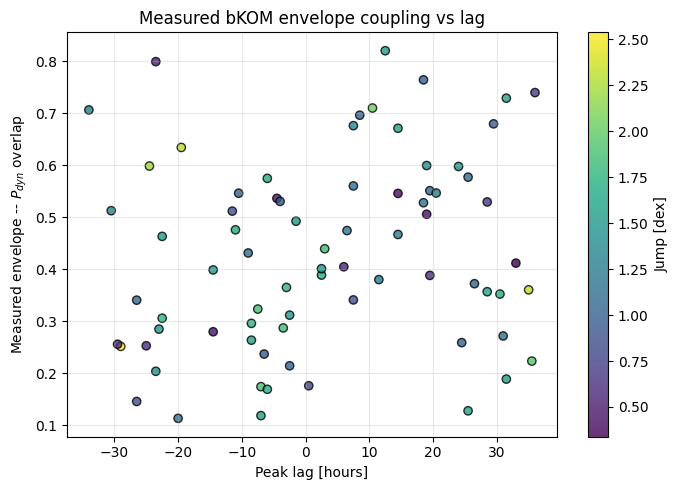

In [75]:
plt.figure(figsize=(7, 5))

plt.scatter(
    df_final["lag_hours_peak"],
    df_final["meas_env_overlap"],
    c=df_final["jump_log"],
    #s=40 * df_final["response_ratio"].clip(1, 10),
    cmap="viridis",
    edgecolor="k",
    alpha=0.8
)

plt.colorbar(label="Jump [dex]")

plt.xlabel("Peak lag [hours]")
plt.ylabel("Measured envelope -- $P_{dyn}$ overlap")

plt.title("Measured bKOM envelope coupling vs lag")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

(G) Representing the entire ensemble that we have so far

(H) Introducing the JSO parameter to divide the study into local time sectors

(I) Shocks Classification into FRS/FFS

(J) Introduing the solar cycle